In [4]:
'''
check out eff predictions on april's eff data
from each fold of nn saved separately
'''

"\ncheck out eff predictions on april's eff data\nfrom each fold of nn saved separately\n"

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
'''waaa'''

In [113]:
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")


In [ ]:
#okay we gotta fix stuff a little and also only pos ran

In [15]:
path = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_4/"
for file in os.listdir(path):
    newfile = file[14:]
    os.rename(path+file,path+newfile)

In [ ]:
#now we average them?

In [16]:
!mkdir "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/"

In [26]:
savedir = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/"

In [28]:
paths = ["/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_0/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_1/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_2/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_3/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_4/"]
for i, file in enumerate(os.listdir(paths[0])):
    arrays = []
    for path in paths:
        arrays.append(np.load(path+file))
    average = np.average(arrays, axis=0)
    np.save(savedir+file, average)


In [23]:
np.array(arrays).shape

(5, 9339120, 6)

In [25]:
np.average(arrays, axis=0).shape

(9339120, 6)

In [ ]:
#okay now running varthresh to match them

In [68]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_*

/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.5
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.6
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.7
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.8
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.85
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.9
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.95
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matche

In [76]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "quad", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [77]:
df.iloc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020138241_000686_zi_c05_x_0000.
quad                                                          1
type                                                        pos
row_from_nn                                                41.6
col_from_nn                                          548.939394
detection_size                                              165
closest_x                                                 559.0
closest_y                                                2317.0
Diff                                                   0.060606
brightness_ranking                                            7
quadrant                                                      1
num_in_file_in_star                                        70.0
dup_indices                                                  []
is_smaller_dup                          

In [107]:
def adjust_num_all_retrieved(dfold, posneg):
    '''
    going to say that the duplicates where there is pos next to neg
    doesn't count for the number of all retrieved
    NOTE only works if iloc=loc
    '''
    df = dfold.copy()
    todrop = []
    if posneg=='pos':
        opposite='neg'
    elif posneg=='neg':
        opposite='pos'
    for i, row in df.iterrows():
        # print(i)
        # break
        if row['type']==opposite:
            for j, otherrow in df.iterrows():
                if otherrow['closest_x']==row['closest_x'] and otherrow['closest_y']==row['closest_y']:
                    if otherrow['type']==posneg:
                        if np.sqrt(((otherrow['row_from_nn']-row['row_from_nn'])**2)+((otherrow['col_from_nn']-row['col_from_nn'])**2))<40:
                            todrop.append(i)
    df.drop(todrop)
    return df, len(df)

In [88]:
len(df)

1268

In [105]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,38.714286,240.071429,42,250.0,1761.0,...,6,1,10.0,[],0.0,0.294508,49.0,250.0,1.50,4.0
1,1,1,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,42.061728,476.086420,81,487.0,435.0,...,1,1,12.0,[],0.0,0.942243,53.0,486.0,10.00,5.0
2,2,2,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,46.745455,1430.381818,55,1441.0,1579.0,...,2,1,6.0,[],0.0,1.398583,58.0,1441.0,1.20,5.0
3,3,3,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,71.750000,2256.916667,24,2266.0,1067.0,...,9,1,4.0,[],0.0,0.950146,82.0,2266.0,5.00,4.0
4,4,4,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,85.644068,2954.305085,59,2964.0,425.0,...,3,1,5.0,[],0.0,1.389831,97.0,2964.0,1.50,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1263,1263,1263,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2376.250000,2028.350000,20,2038.0,1087.0,...,0,3,22.0,[],0.0,11.755212,2398.0,2038.0,2.00,5.0
1264,1264,1264,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2401.161290,2028.387097,62,2038.0,1087.0,...,0,3,22.0,[],0.0,13.166982,2398.0,2038.0,2.00,5.0
1265,1265,1265,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2455.254237,2557.593220,59,2568.0,2214.0,...,7,3,7.0,[],0.0,13.260478,2452.0,2568.0,2.00,5.0
1266,1266,1266,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2513.800000,1150.200000,5,1161.0,296.0,...,2,3,8.0,[],0.0,71.804457,2452.0,1161.0,1.15,6.0


In [108]:
newdf, num = adjust_num_all_retrieved(df, 'pos')

In [109]:
print(num, len(df))

1268 1268


In [126]:
def plot_precision_recall_from_eff_data(test_name, df_implants_pos, df_implants_neg,spacing="thresh", threshes = [ "0.5","0.6","0.7","0.8","0.85","0.9","0.95", "0.98","0.99","0.999","0.9999"], subset=None):
     #["0.2","0.3","0.4","0.5","0.6","0.7",
    threshold=20
    precisions_pos = np.zeros(len(threshes))
    recalls_pos = np.zeros(len(threshes))
    precisions_neg = np.zeros(len(threshes))
    recalls_neg = np.zeros(len(threshes))
    for i, thr in enumerate(threshes):
        for posneg in ["pos"]:#,"neg"]:
            df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            if subset!=None:
                df_implants_pos = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
                df_implants_neg = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
                ignore_mask_pos = (np.abs(df['dist_to_implant'])<25)*(df['A_from_implant']<(1+subset))
                df = df[~ignore_mask_pos]
            if posneg=="pos":
                cut_len, implant_len = get_efficiency(df, df_implants_pos, threshold, posneg)
                # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                # print(precision)
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
                # print(recall)
                precisions_pos[i]=precision
                recalls_pos[i]=recall
            else:
                cut_len, implant_len = get_efficiency(df, df_implants_neg, threshold, posneg)
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_neg))
                precisions_neg[i]=precision
                recalls_neg[i]=recall
    if spacing!="thresh":
        threshes = np.array(threshes).astype(float)
    plt.plot(threshes, precisions_pos, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    plt.plot(
        threshes,
        precisions_neg,
        label="Precision, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#cc79a7",
    )
    plt.plot(threshes, recalls_pos, label="Recall, Brightening", linewidth=3, c="#009e73")
    plt.plot(
        threshes,
        recalls_neg,
        label="Recall, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#009e73",
    )

    plt.legend(fontsize=18)
    plt.title(
        "Precision and Recall Curves from Eff Data for Brightening and Dimming Transients: "+test_name+", with subset >"+str(subset), fontsize=18)
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    return precisions_pos, recalls_pos, precisions_neg, recalls_neg

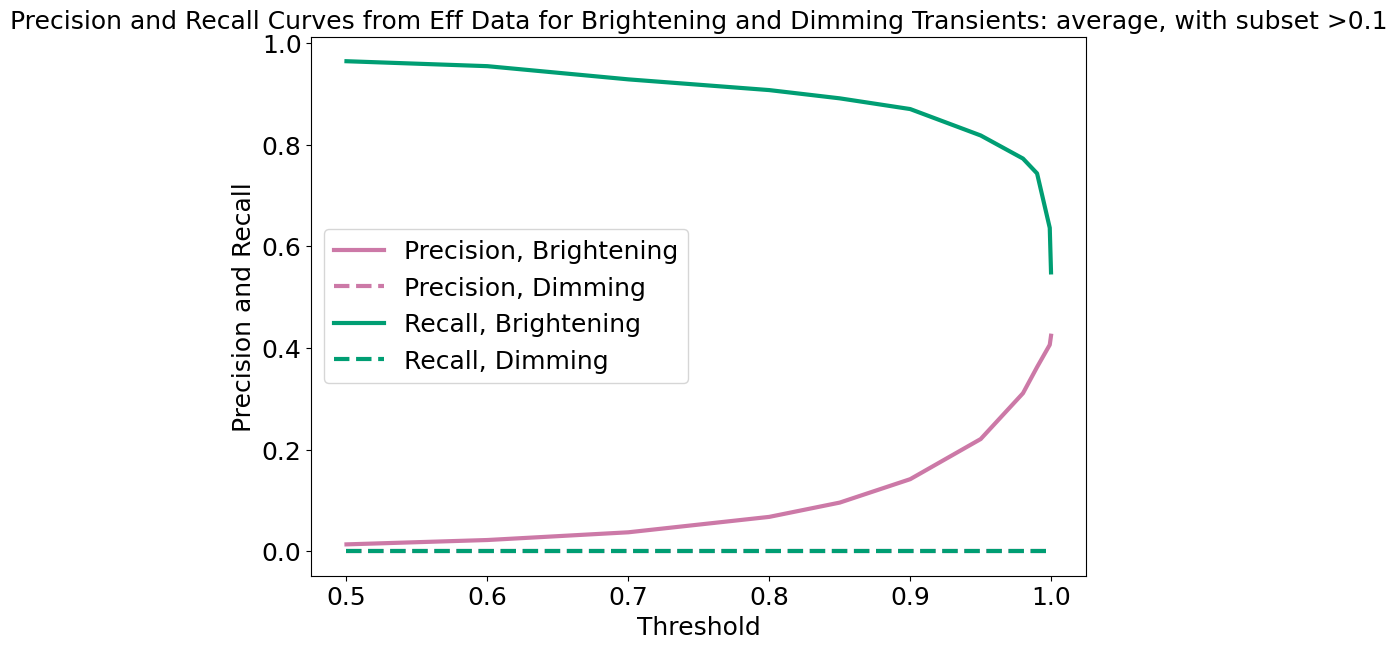

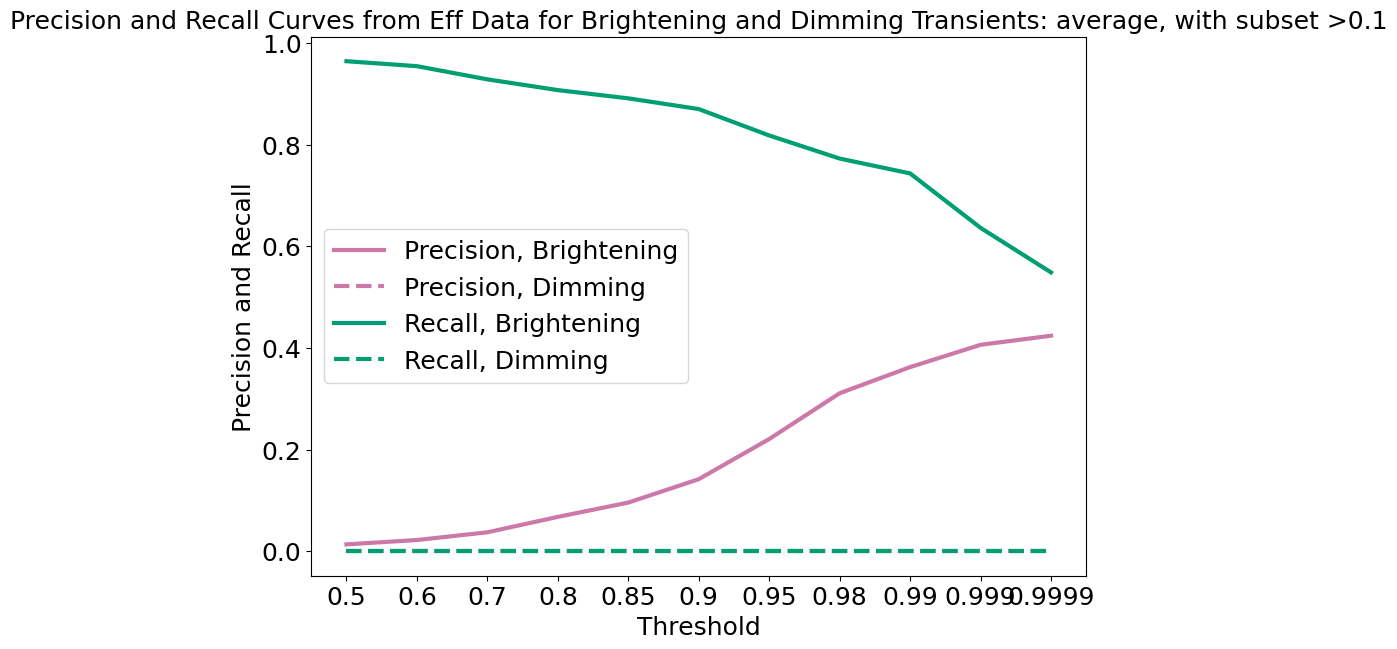

(array([0.01348162, 0.02205303, 0.03724686, 0.06759371, 0.0957113 ,
        0.14179894, 0.22076216, 0.3109079 , 0.36234177, 0.40621762,
        0.42409034]),
 array([0.96428571, 0.95454545, 0.92857143, 0.90746753, 0.89123377,
        0.87012987, 0.81818182, 0.77272727, 0.74350649, 0.63636364,
        0.5487013 ]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]))

In [127]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', subset=.1)
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', subset=.1)

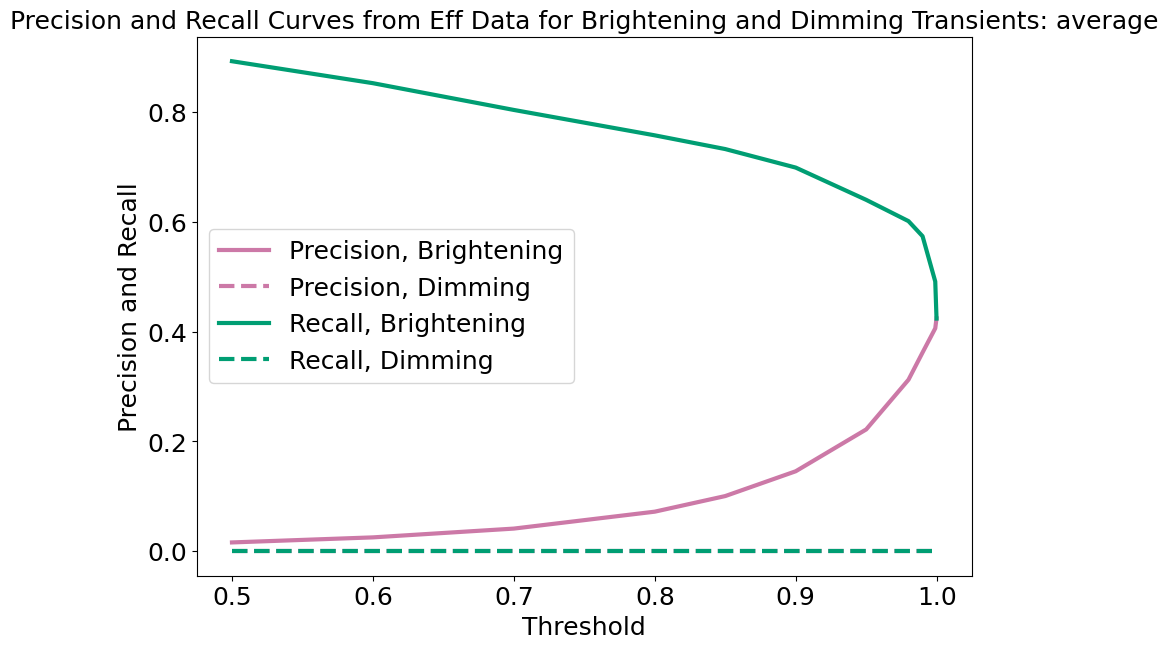

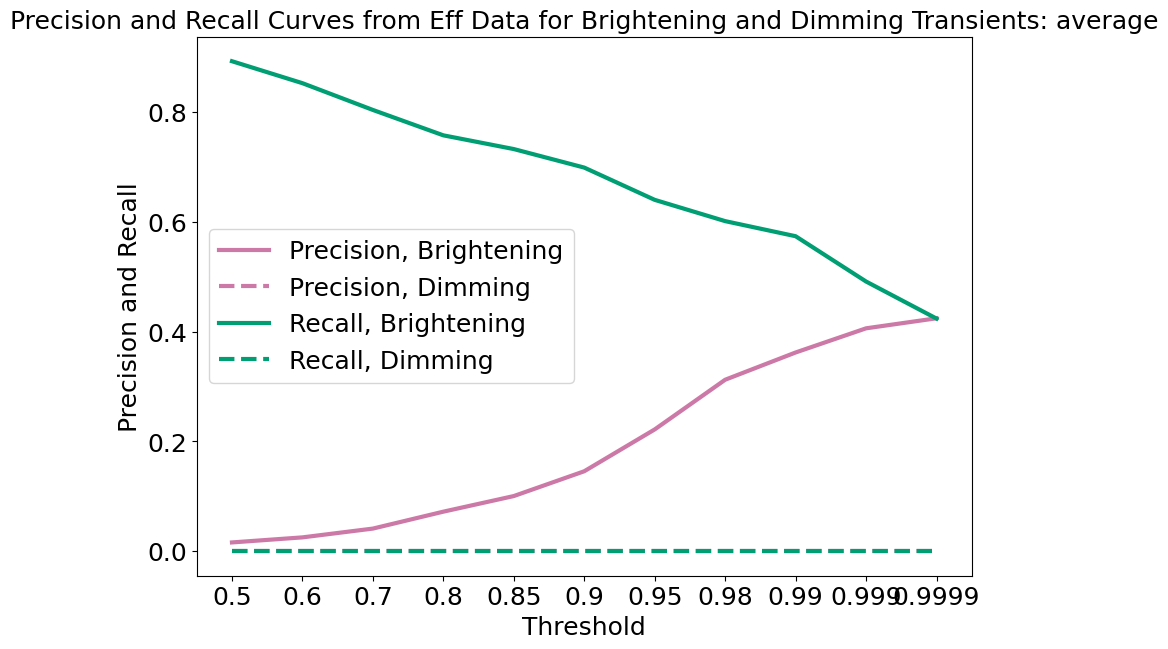

(array([0.01600861, 0.02521816, 0.04122323, 0.07204851, 0.10048011,
        0.14564878, 0.22183709, 0.31233766, 0.36198738, 0.40599174,
        0.42428035]),
 array([0.8925 , 0.8525 , 0.80375, 0.7575 , 0.7325 , 0.69875, 0.64   ,
        0.60125, 0.57375, 0.49125, 0.42375]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]))

In [115]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new')
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh')

In [137]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.5")

In [138]:
len(df)

44601

(array([279.,   0.,   0., 269.,   0.,   0., 266.,   0.,   0., 231.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

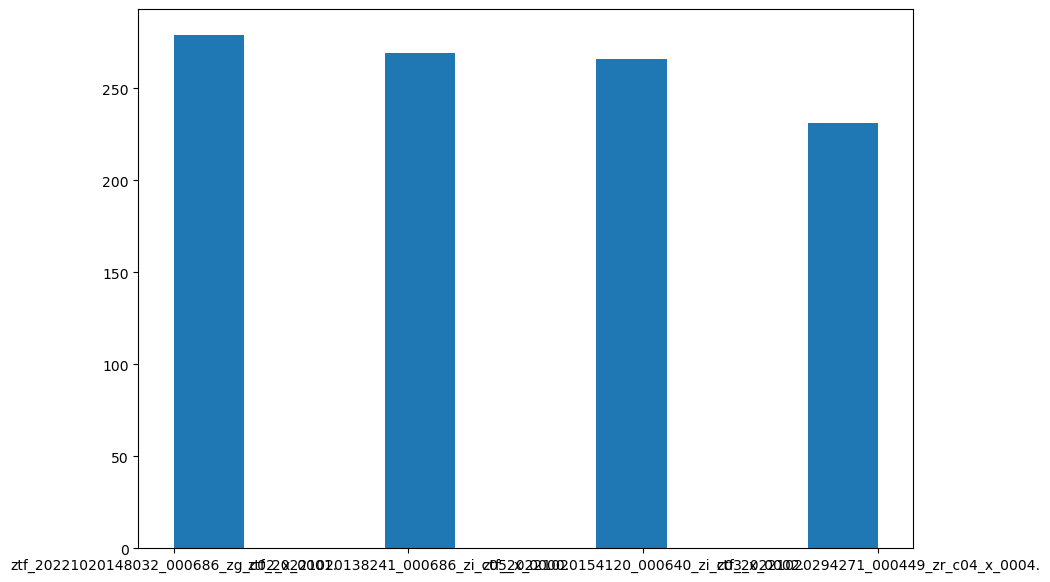

In [87]:
plt.hist(df[df['dist_to_implant']<20]['filename'])

In [56]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

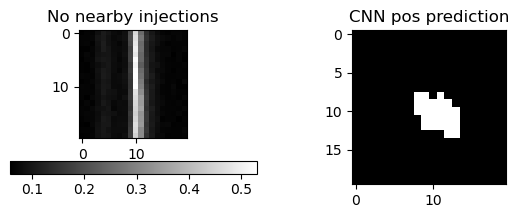

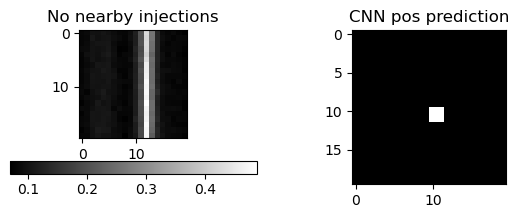

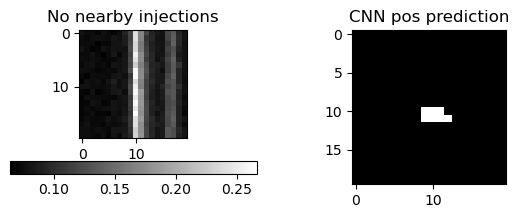

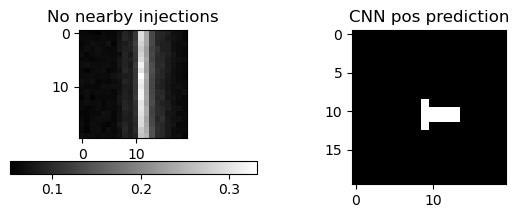

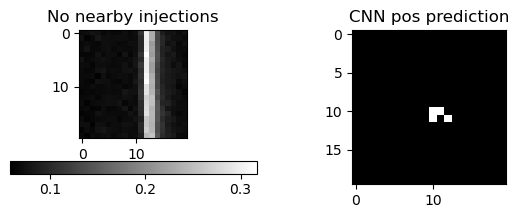

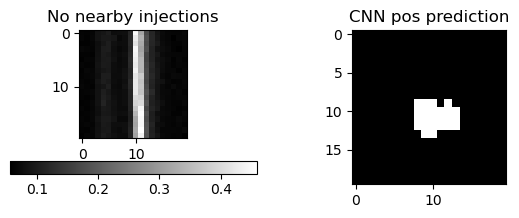

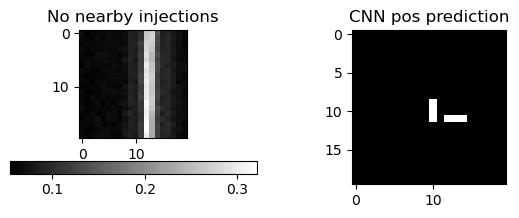

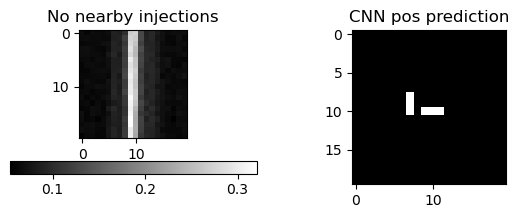

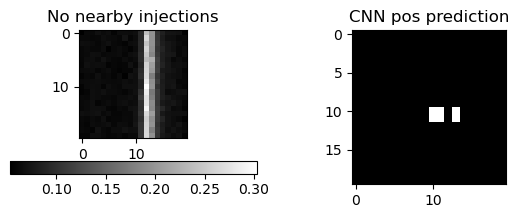

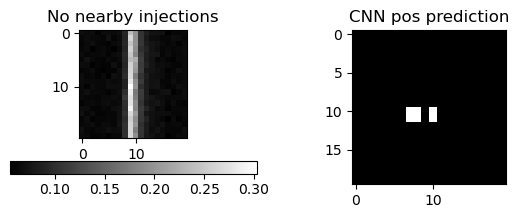

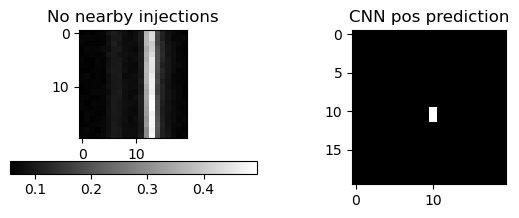

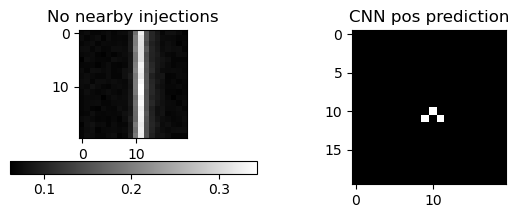

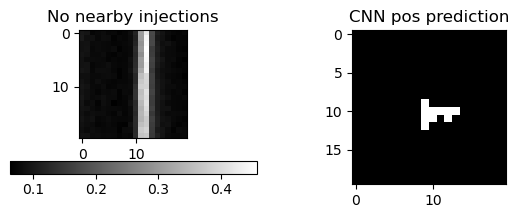

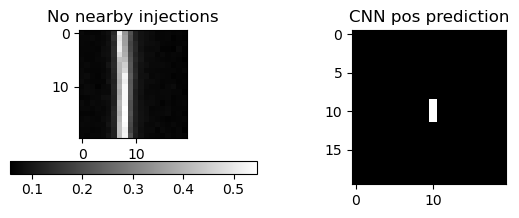

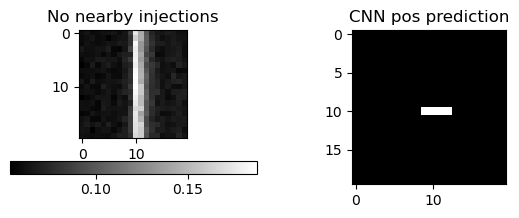

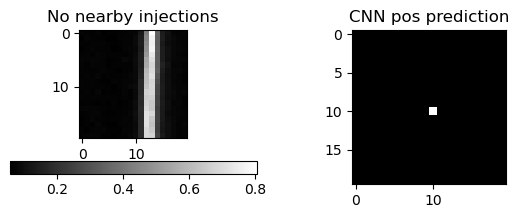

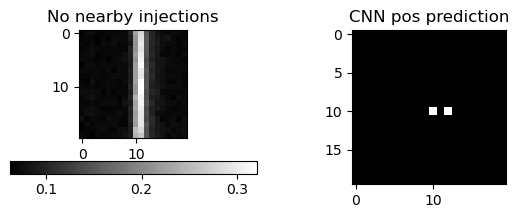

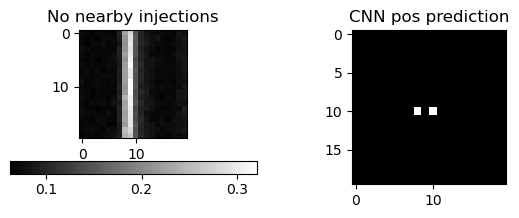

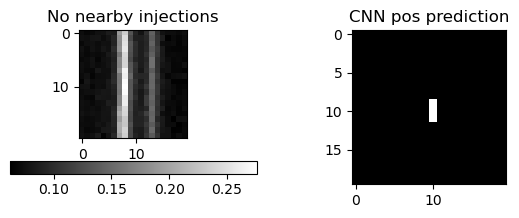

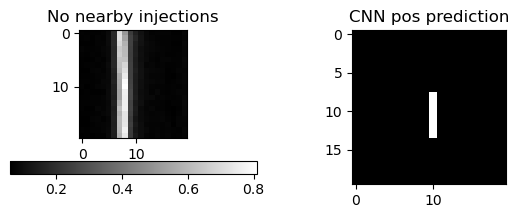

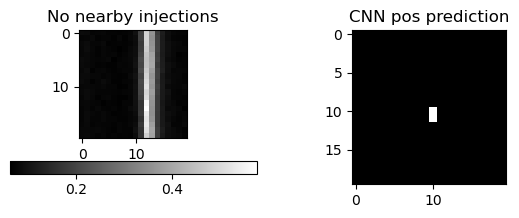

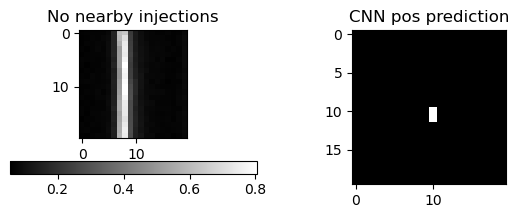

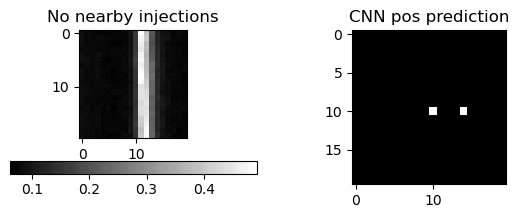

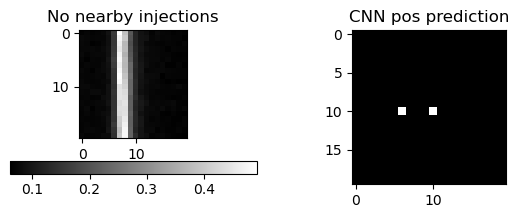

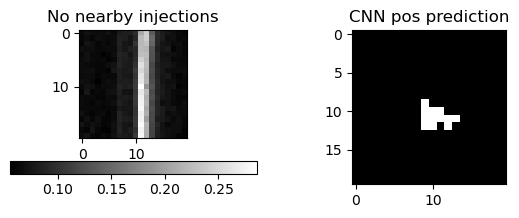

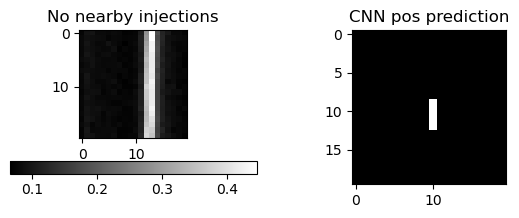

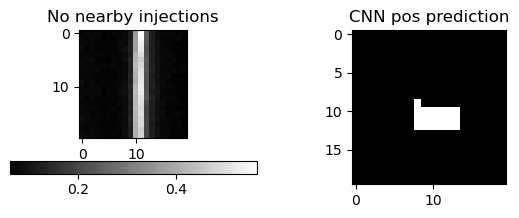

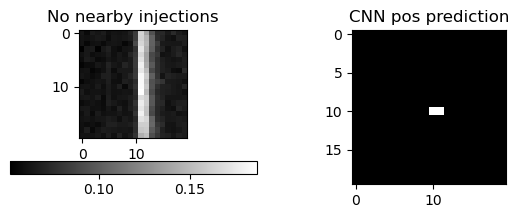

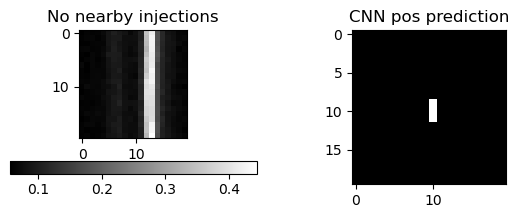

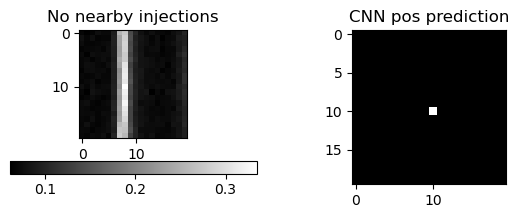

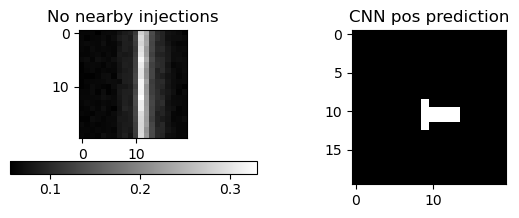

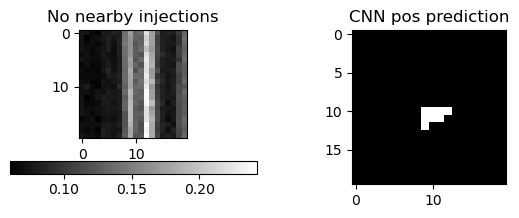

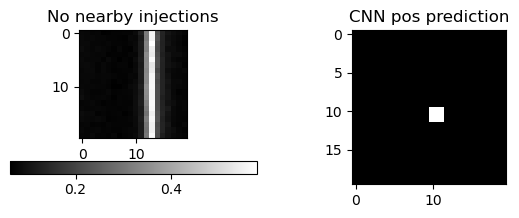

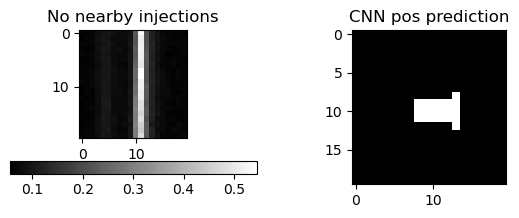

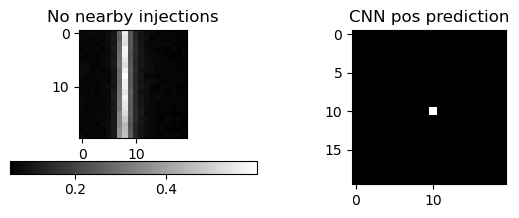

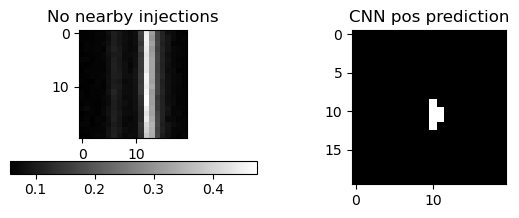

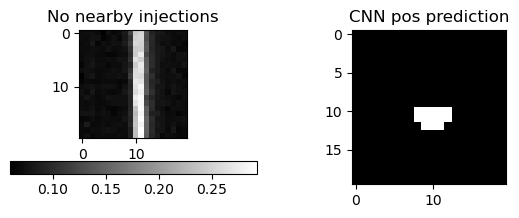

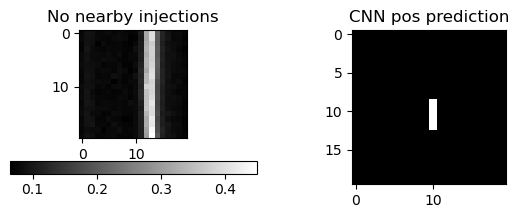

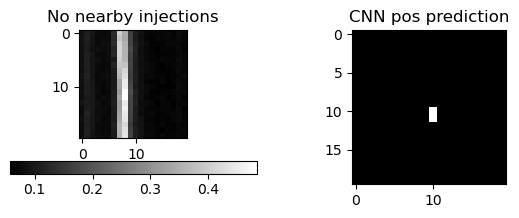

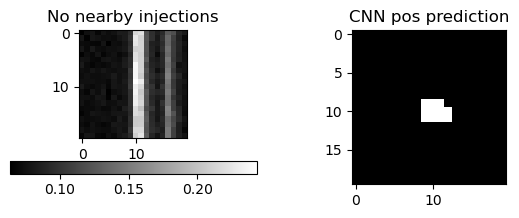

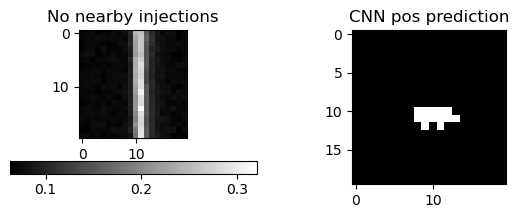

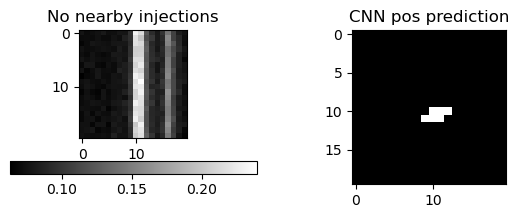

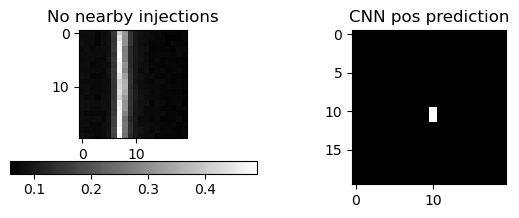

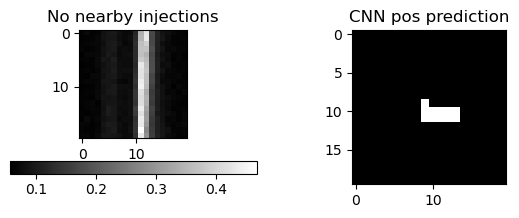

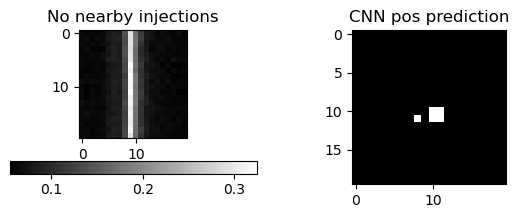

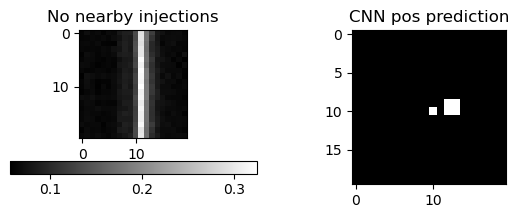

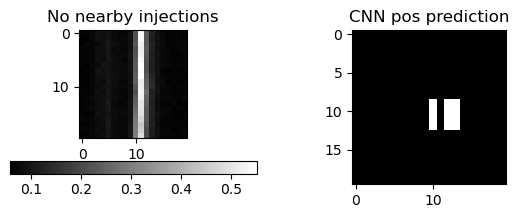

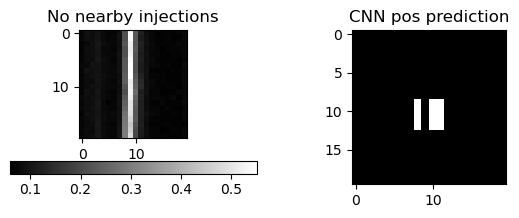

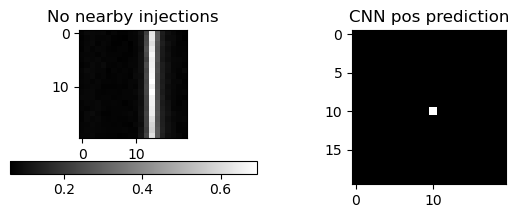

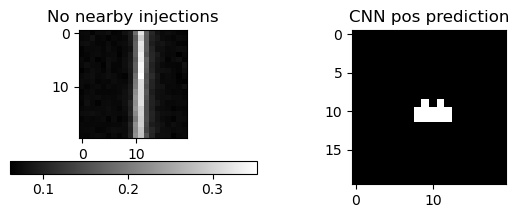

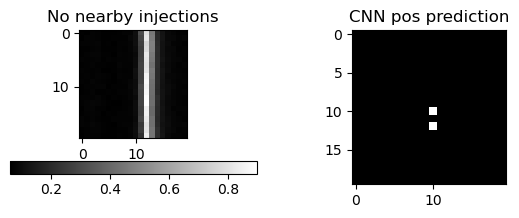

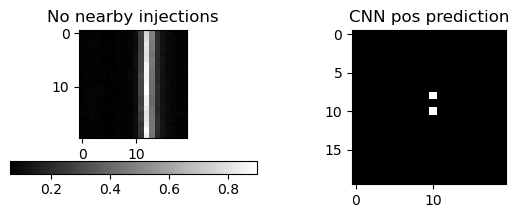

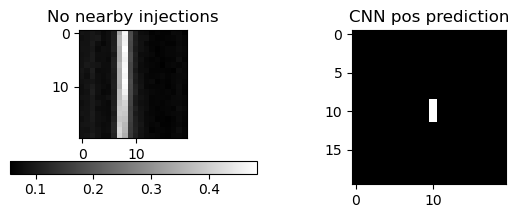

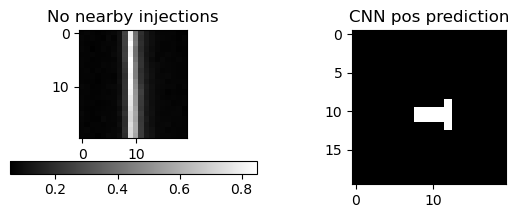

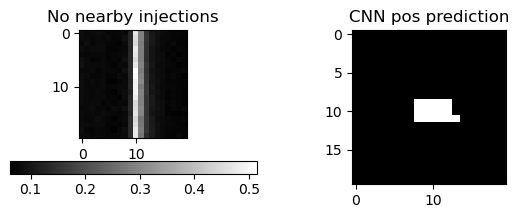

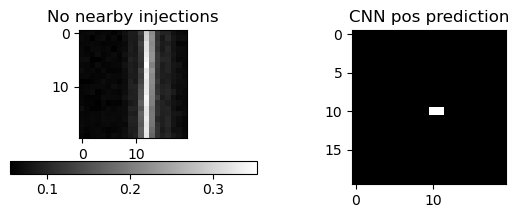

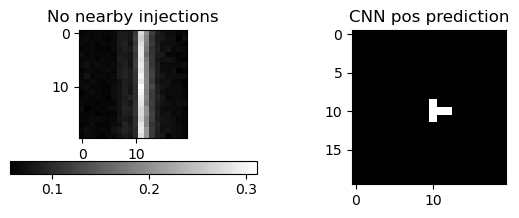

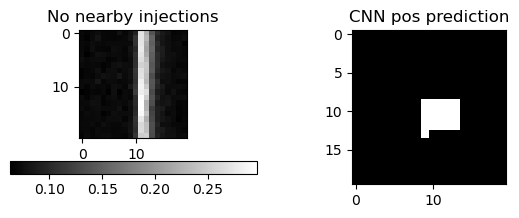

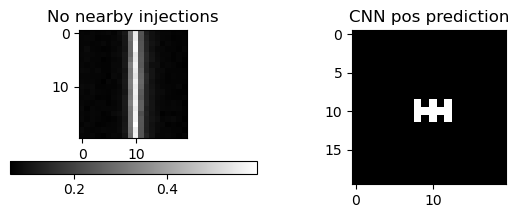

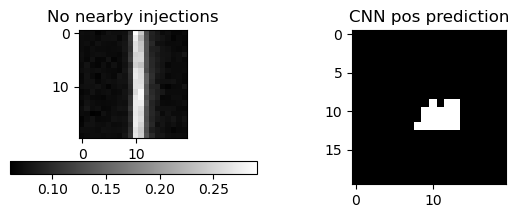

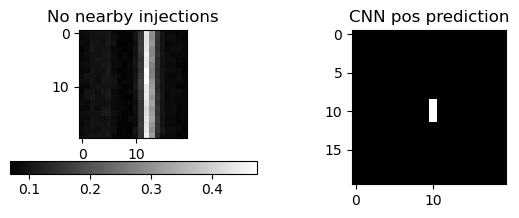

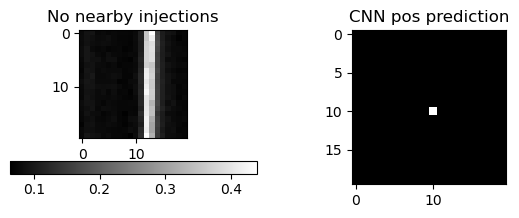

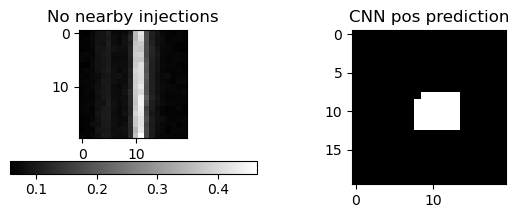

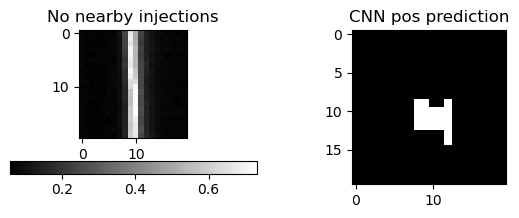

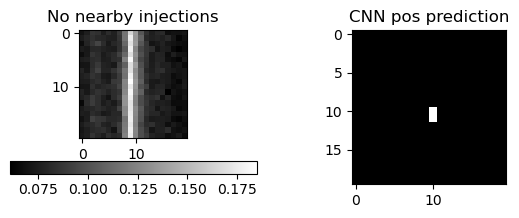

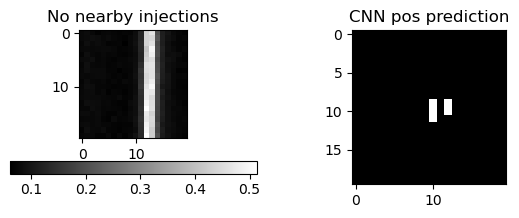

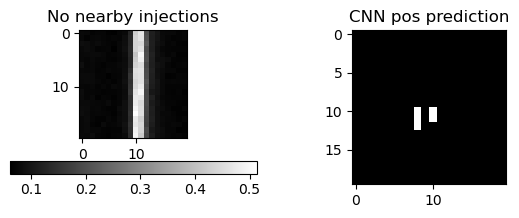

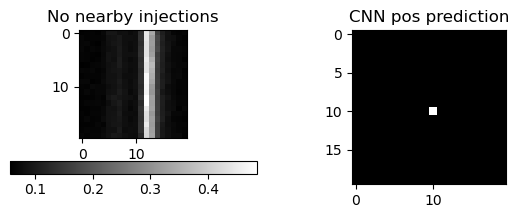

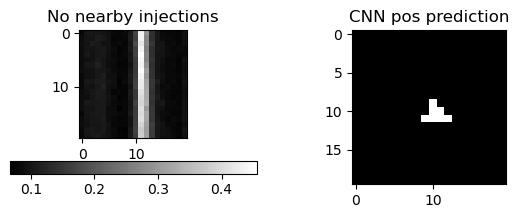

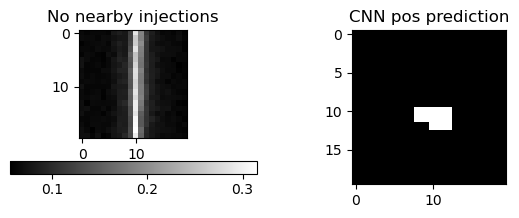

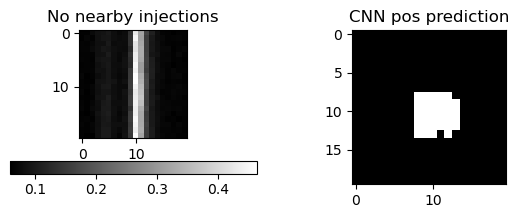

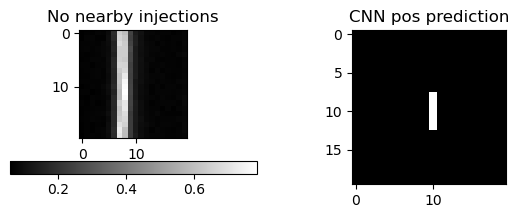

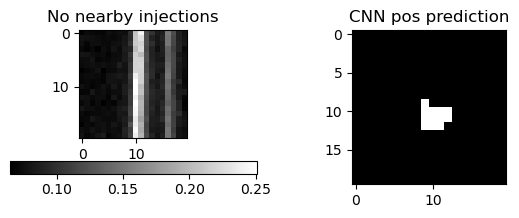

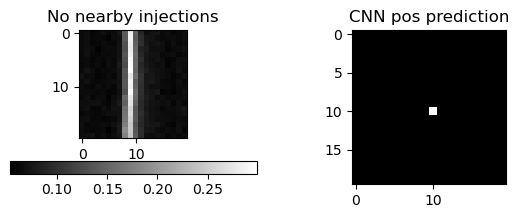

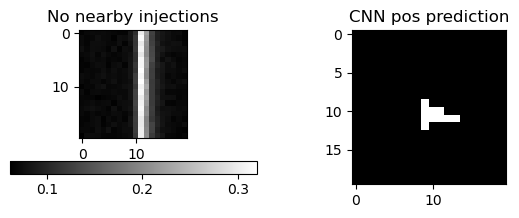

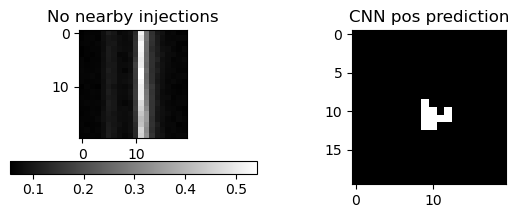

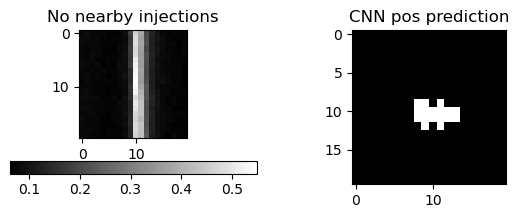

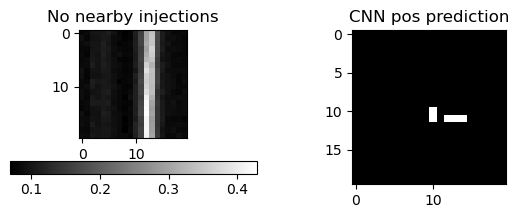

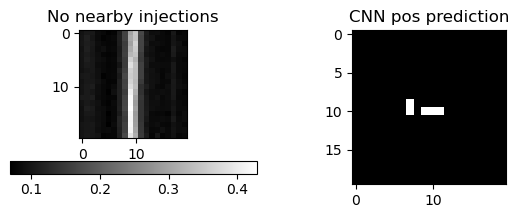

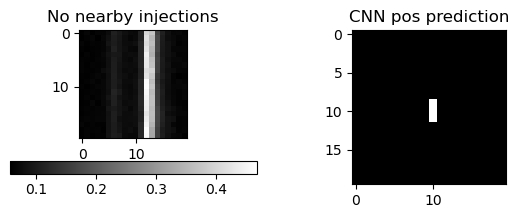

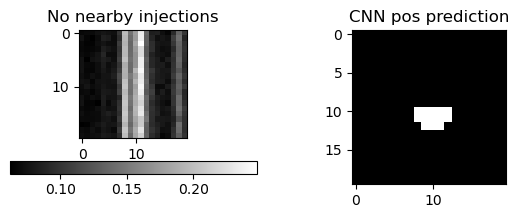

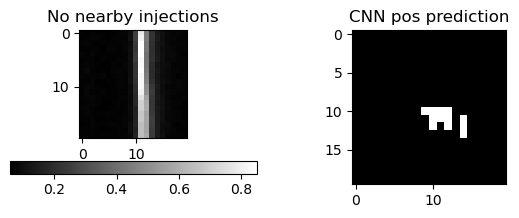

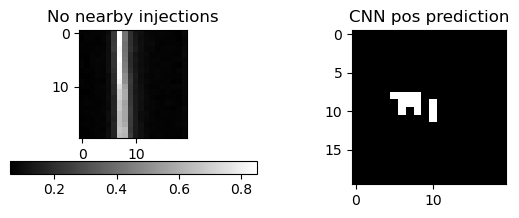

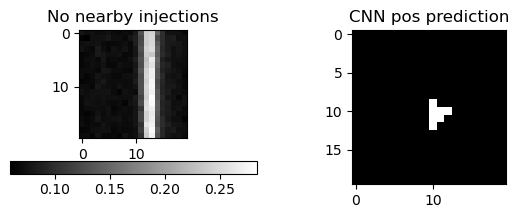

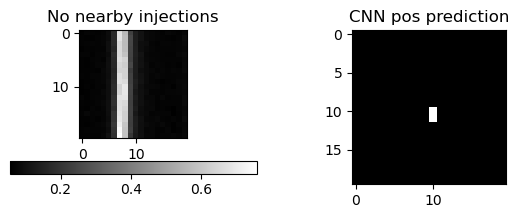

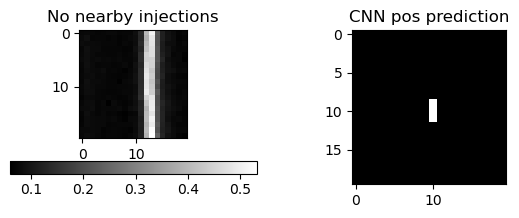

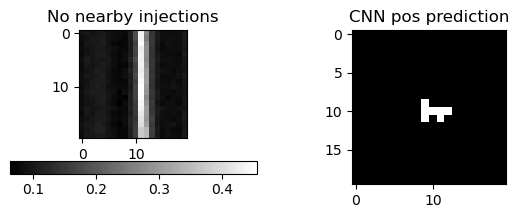

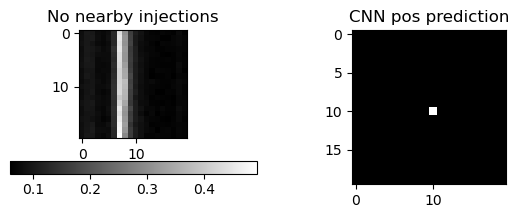

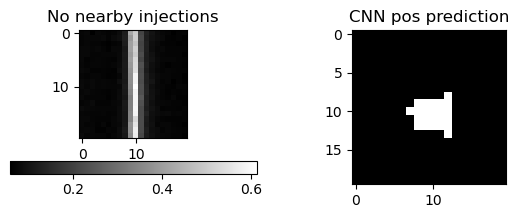

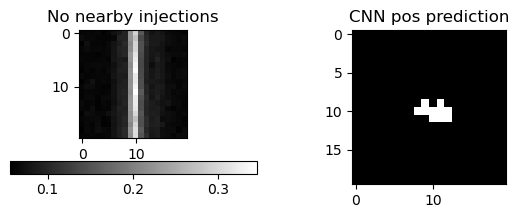

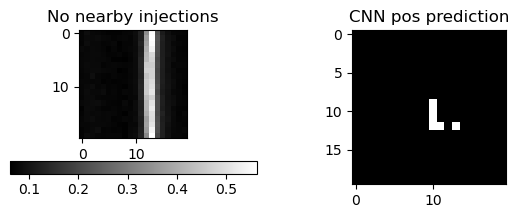

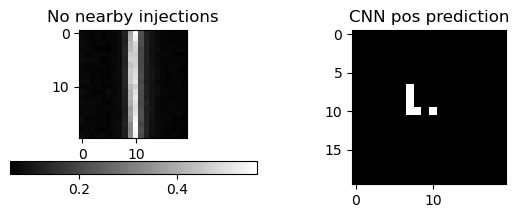

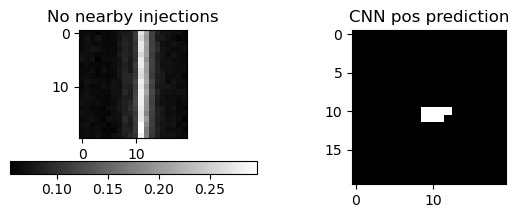

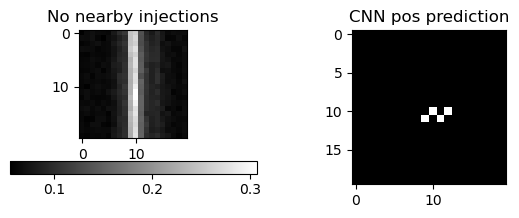

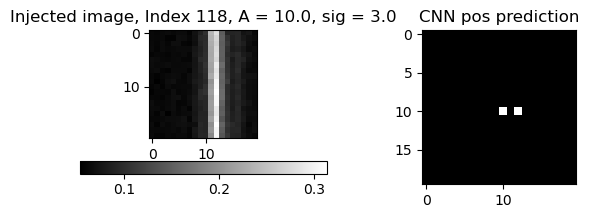

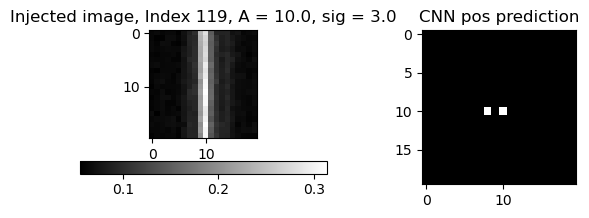

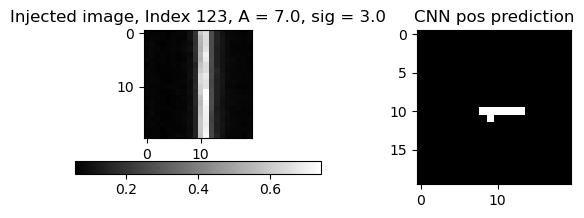

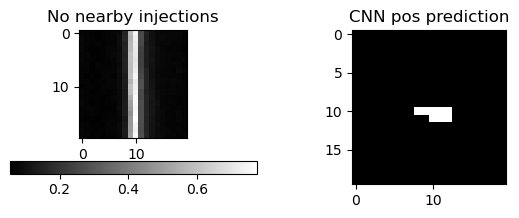

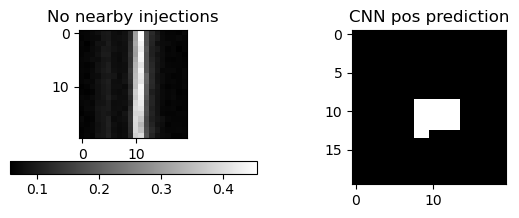

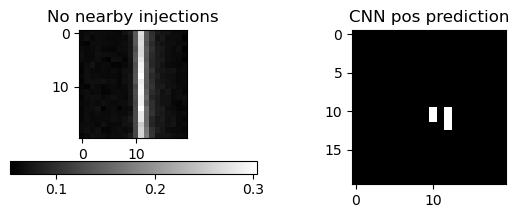

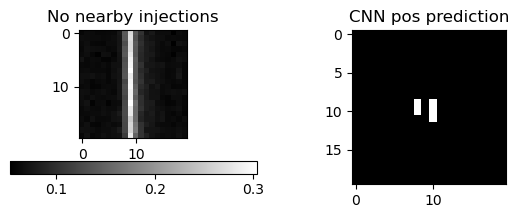

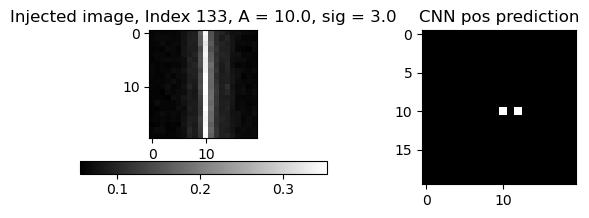

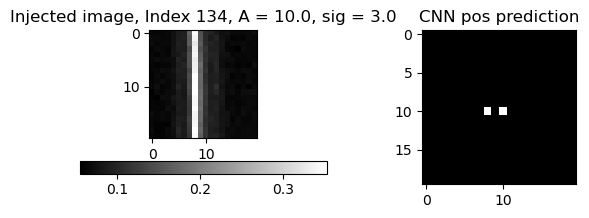

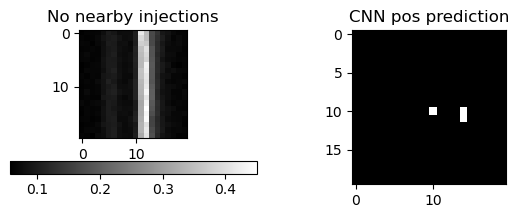

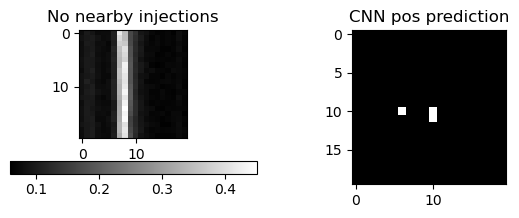

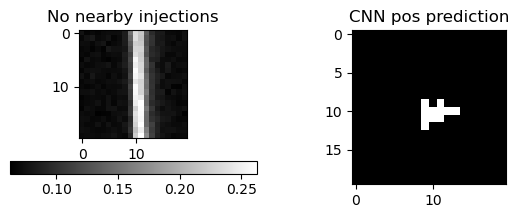

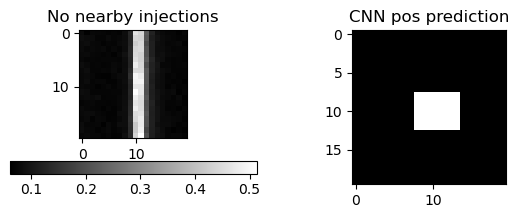

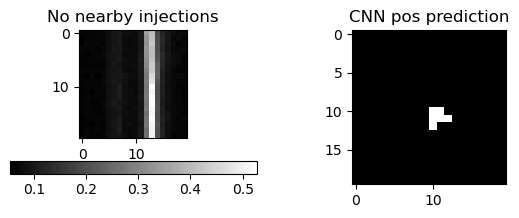

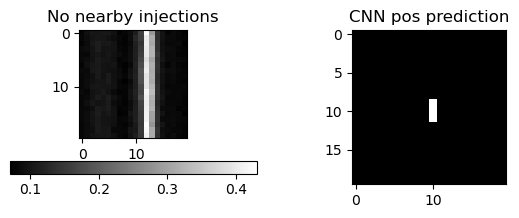

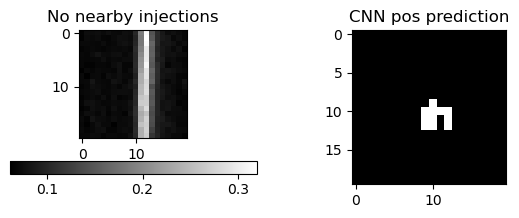

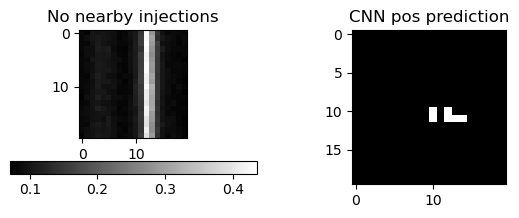

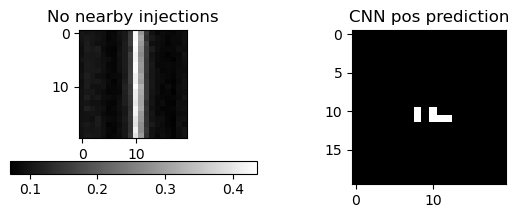

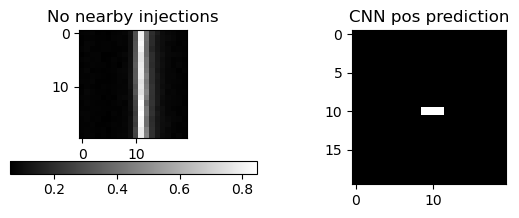

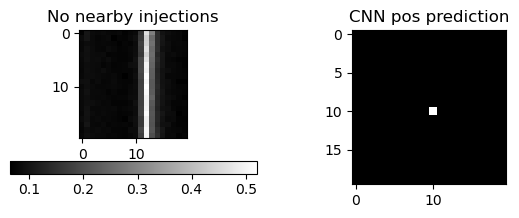

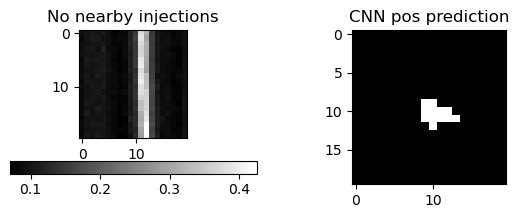

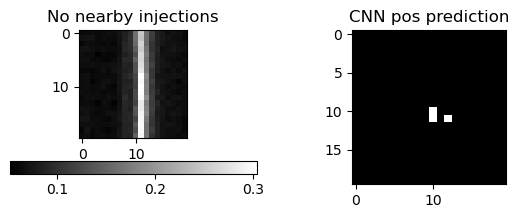

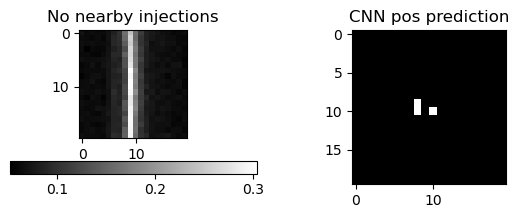

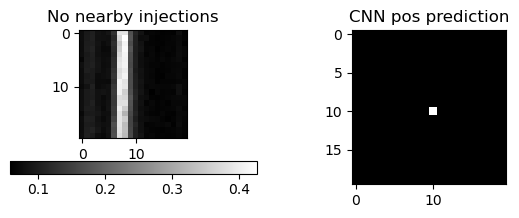

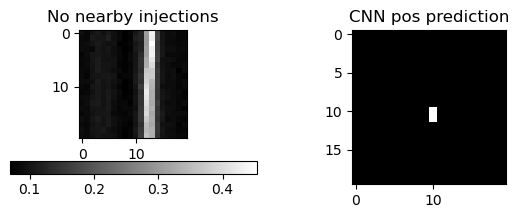

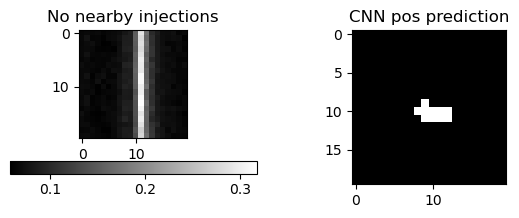

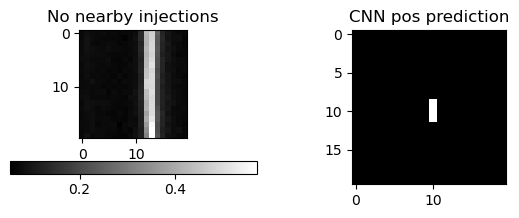

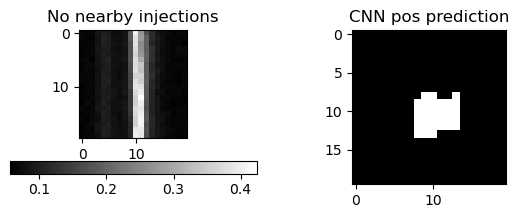

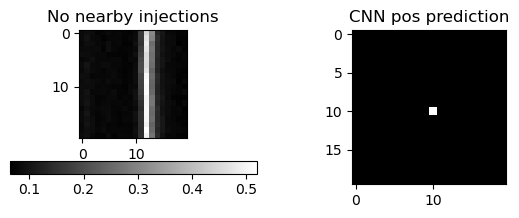

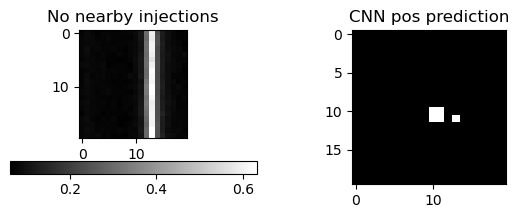

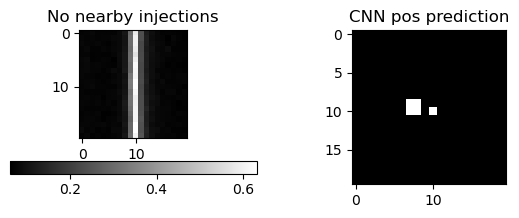

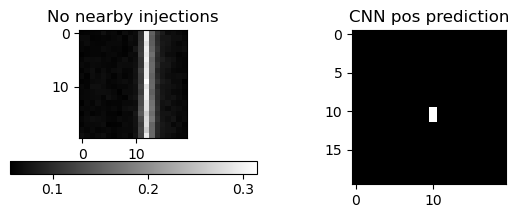

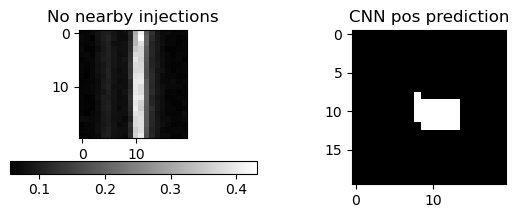

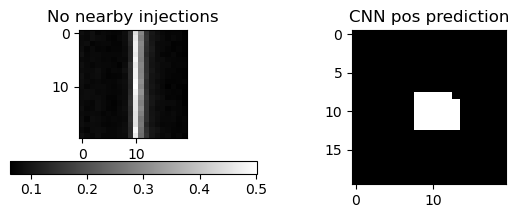

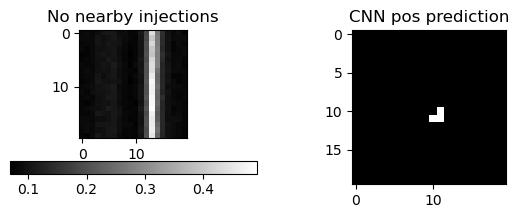

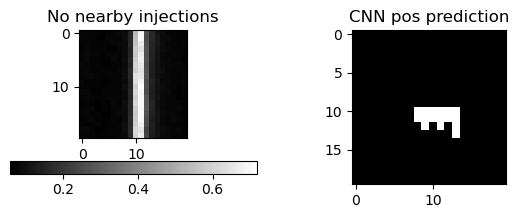

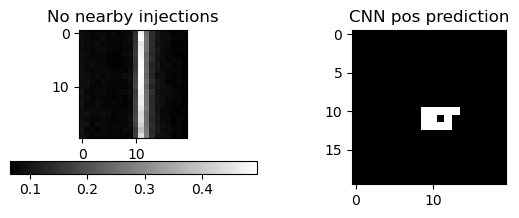

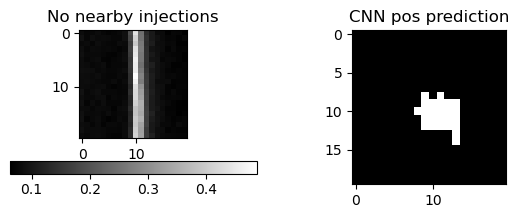

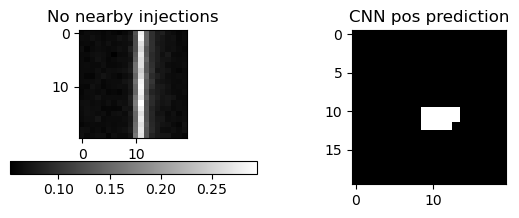

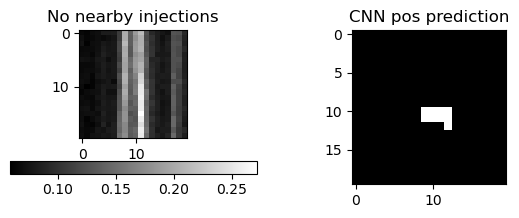

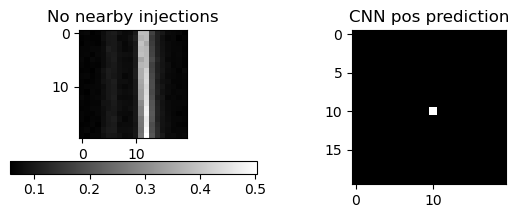

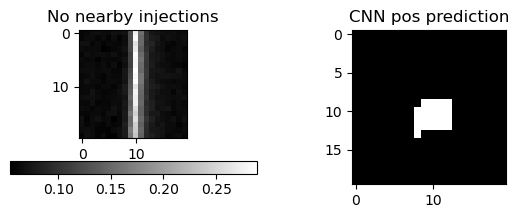

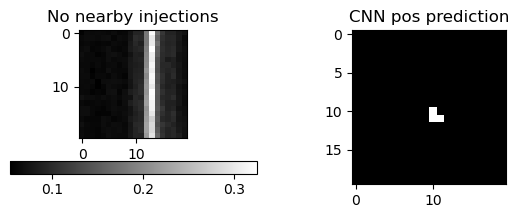

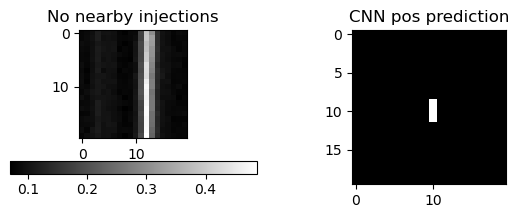

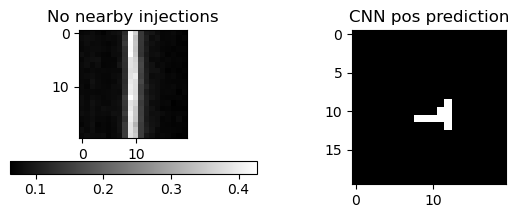

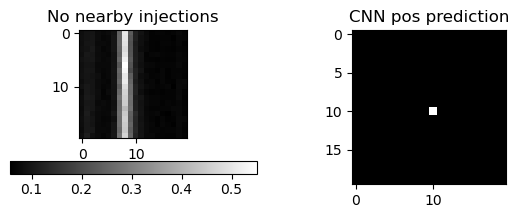

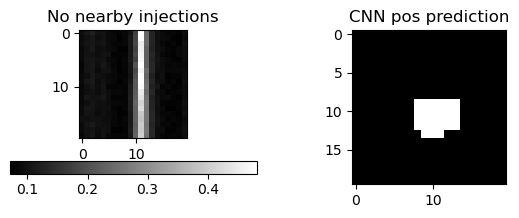

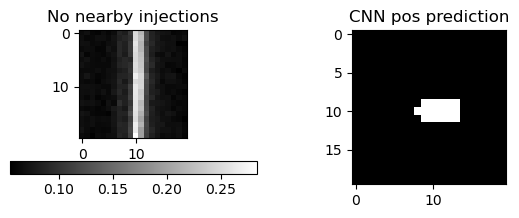

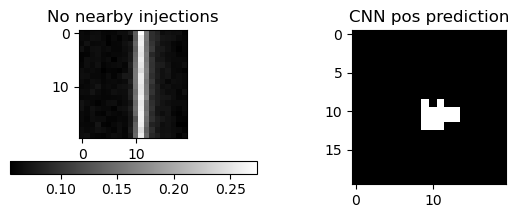

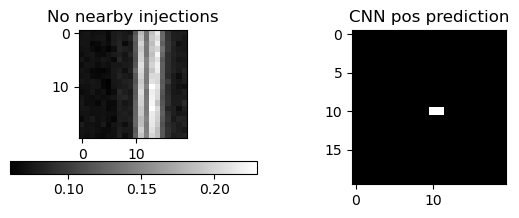

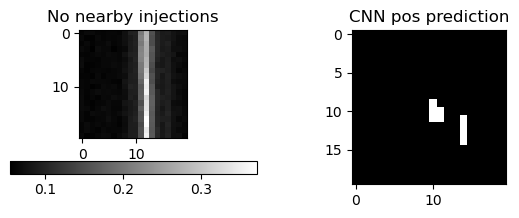

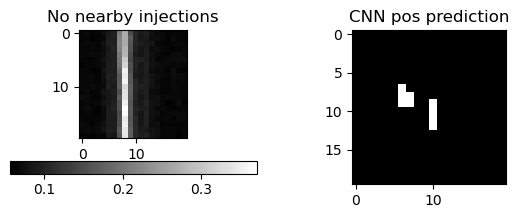

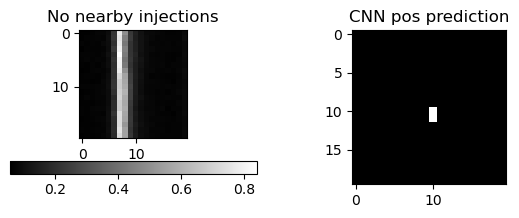

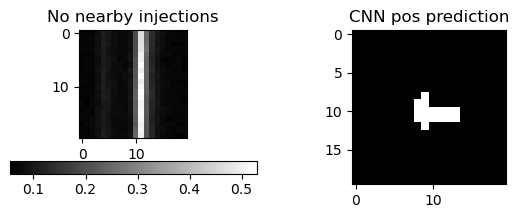

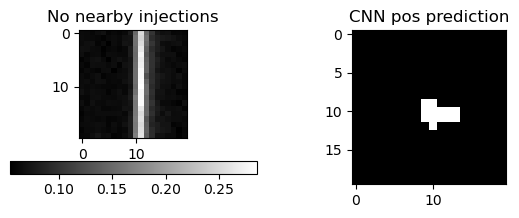

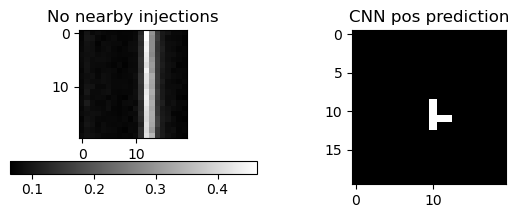

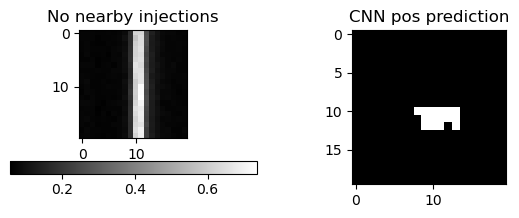

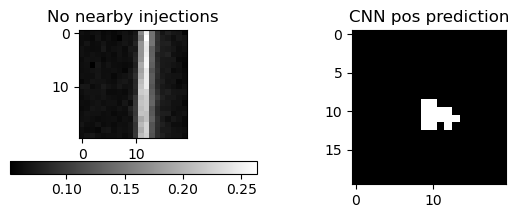

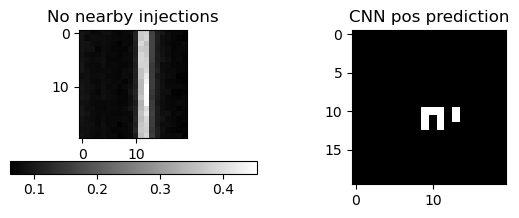

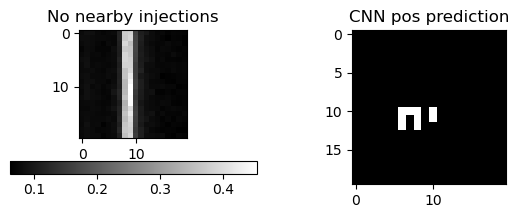

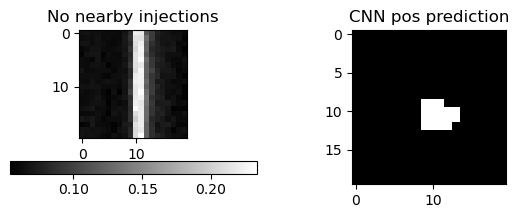

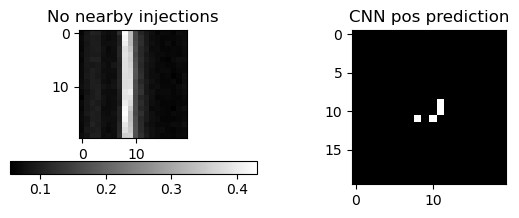

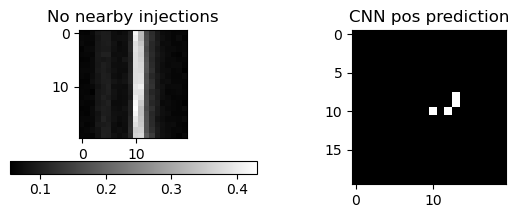

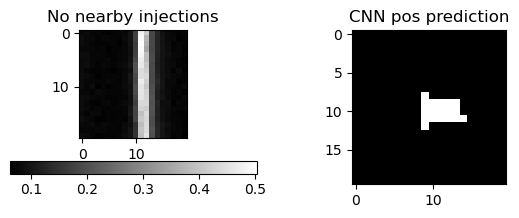

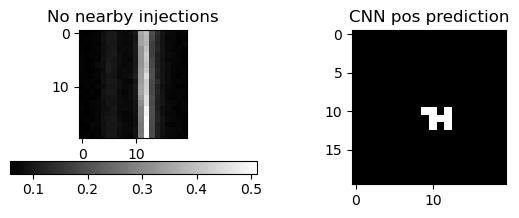

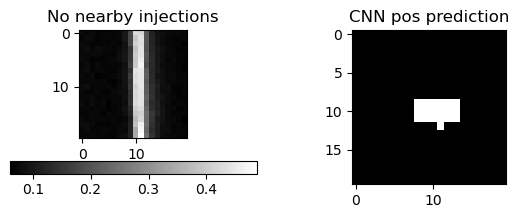

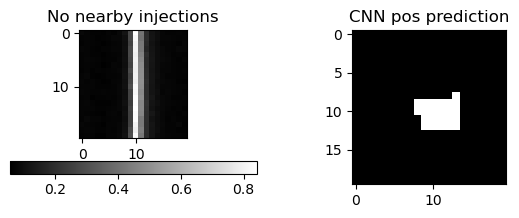

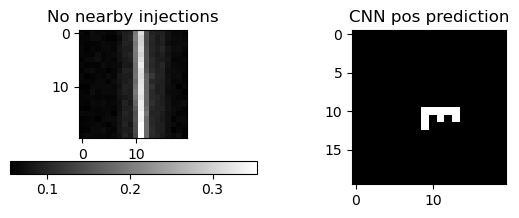

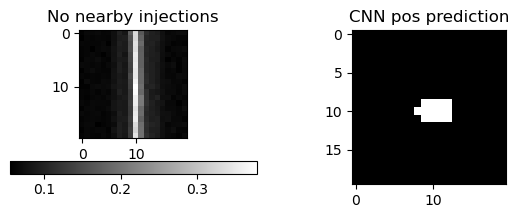

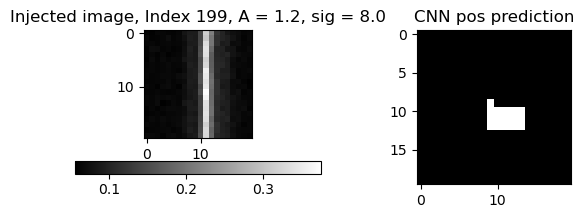

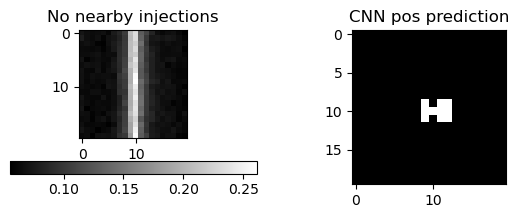

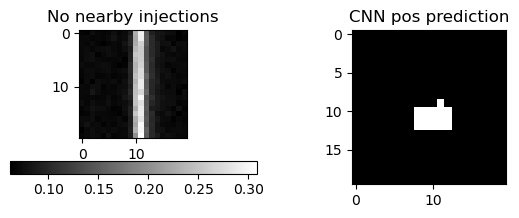

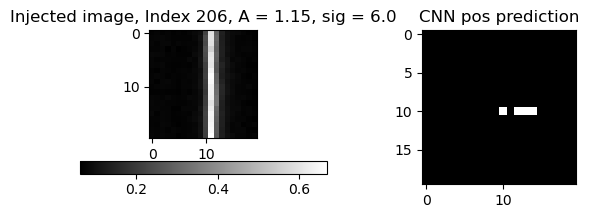

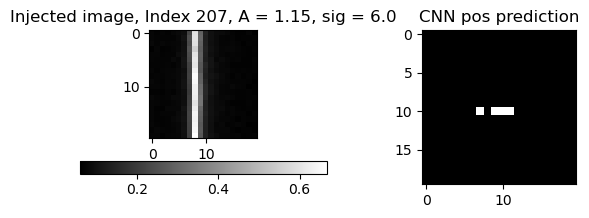

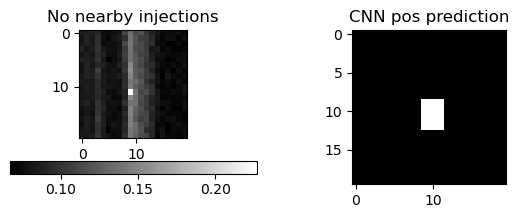

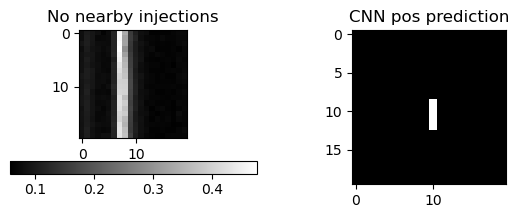

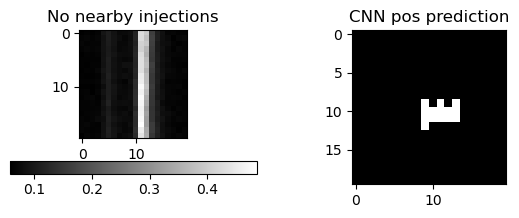

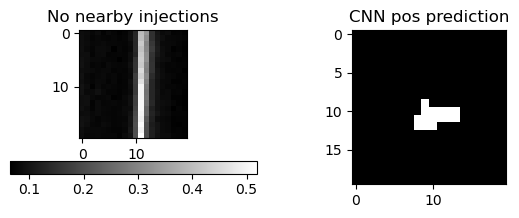

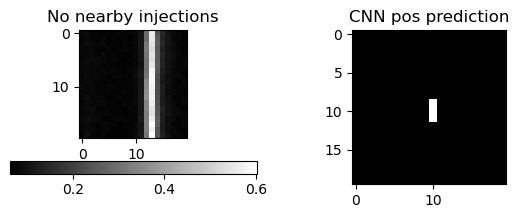

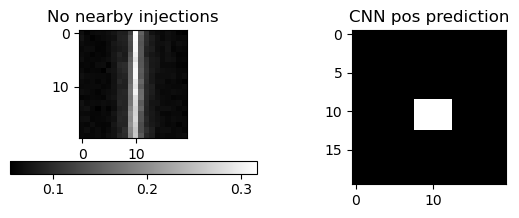

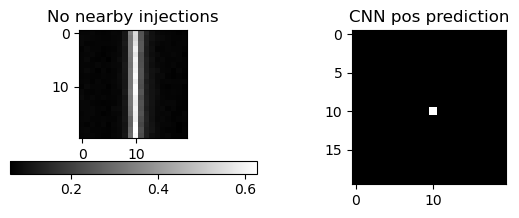

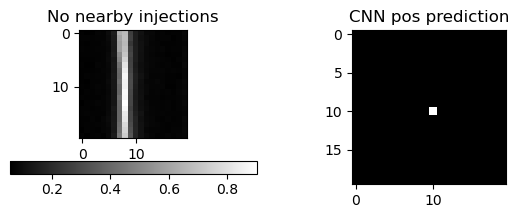

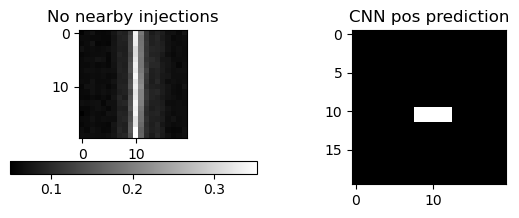

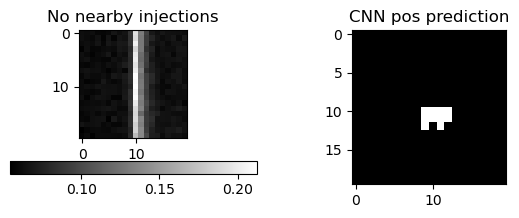

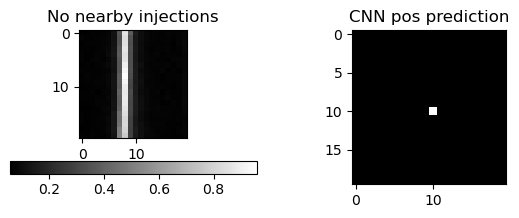

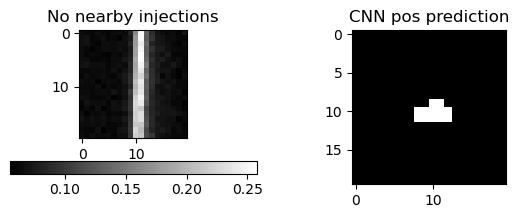

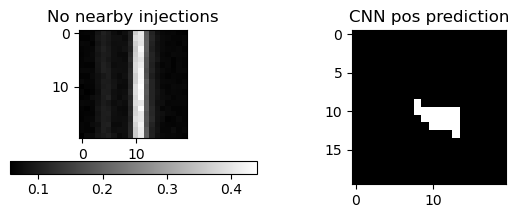

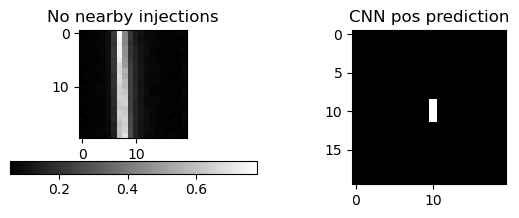

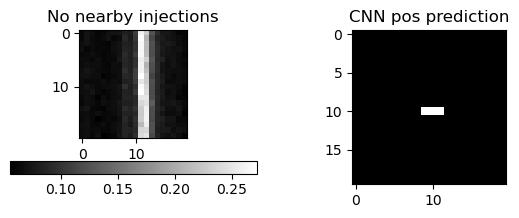

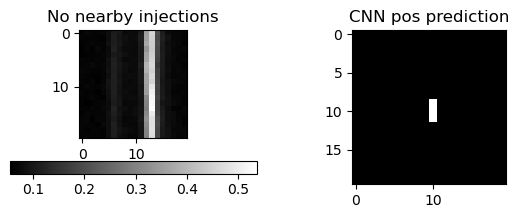

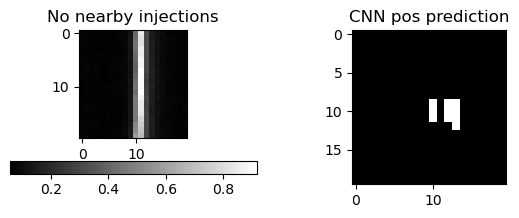

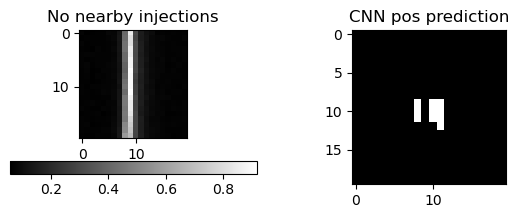

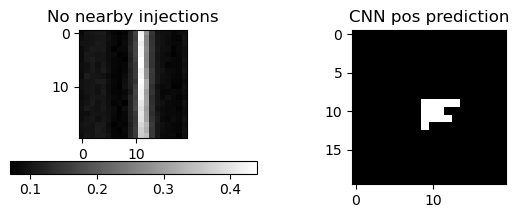

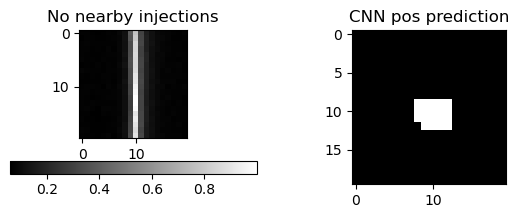

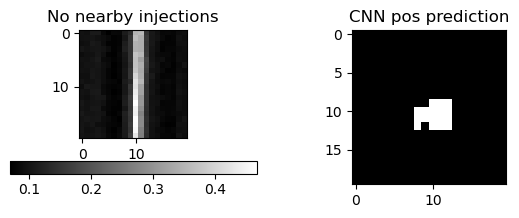

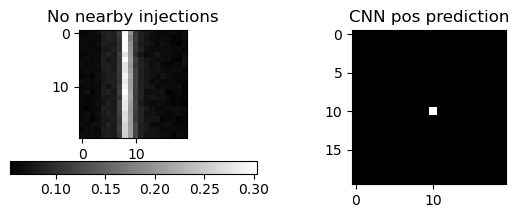

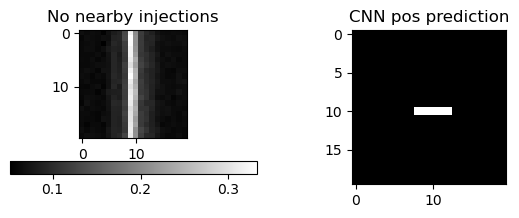

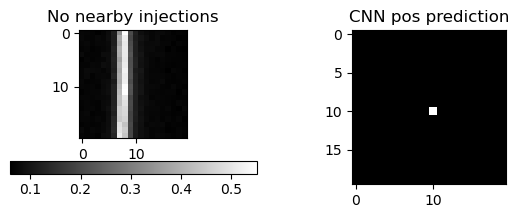

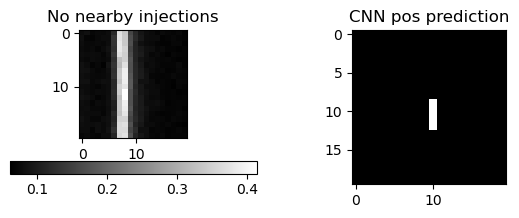

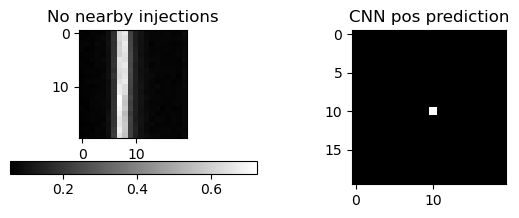

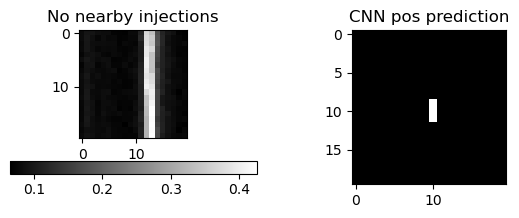

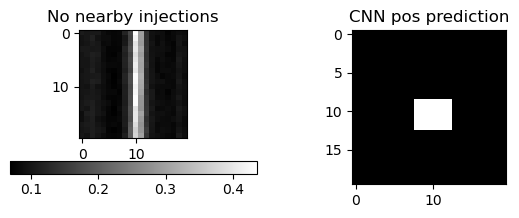

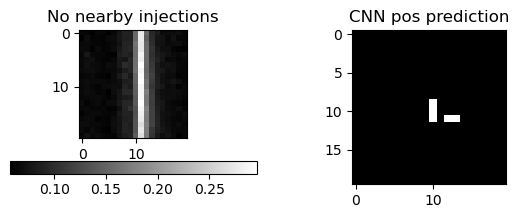

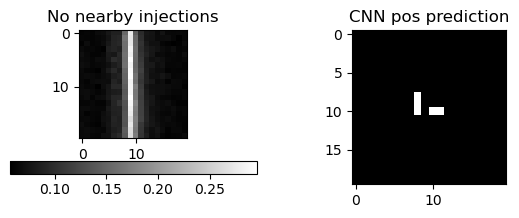

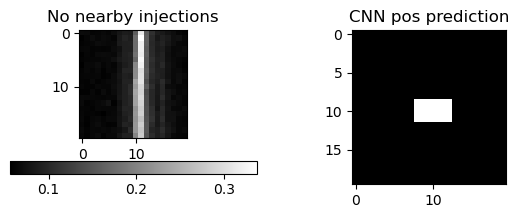

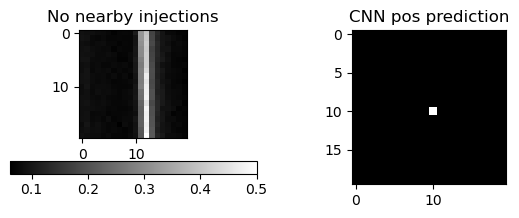

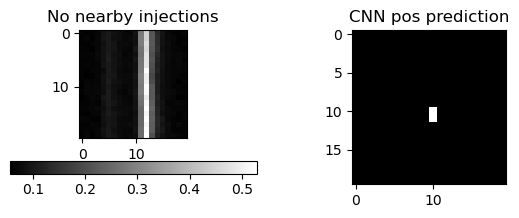

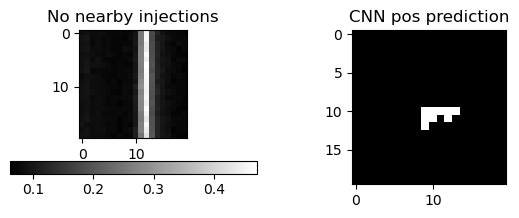

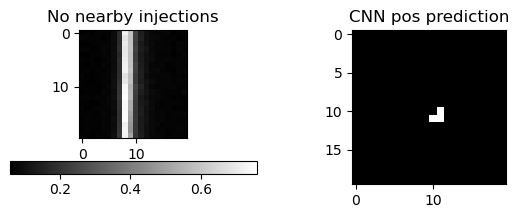

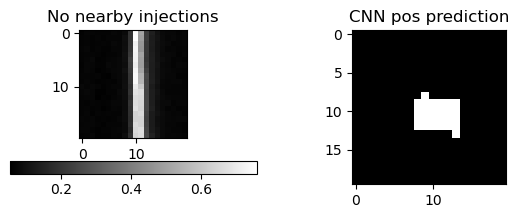

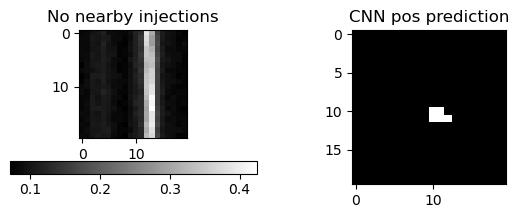

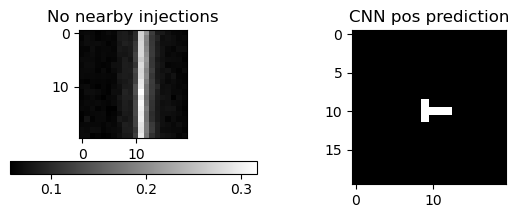

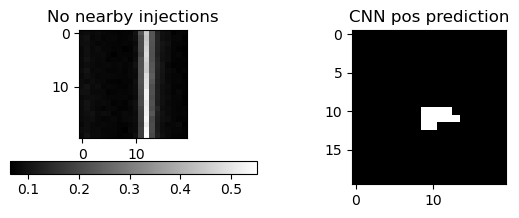

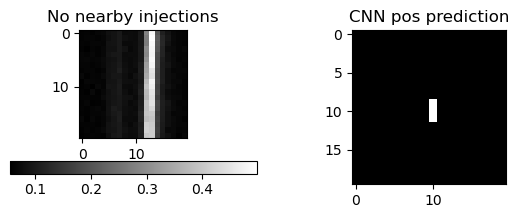

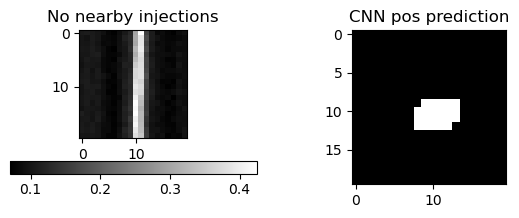

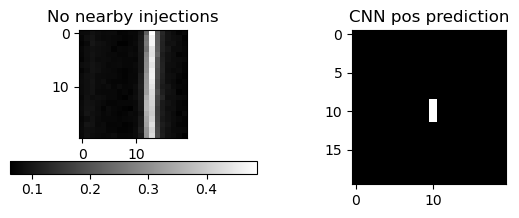

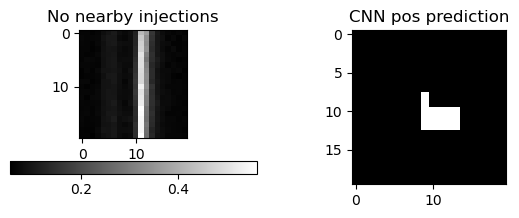

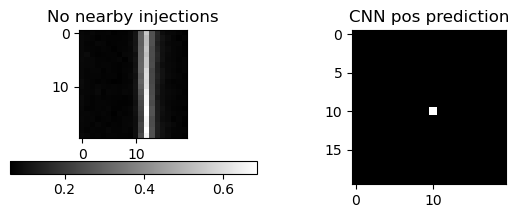

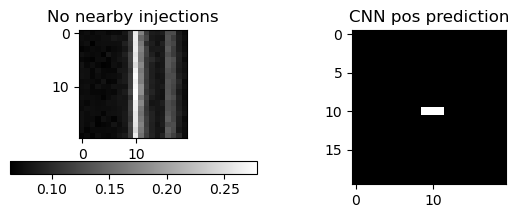

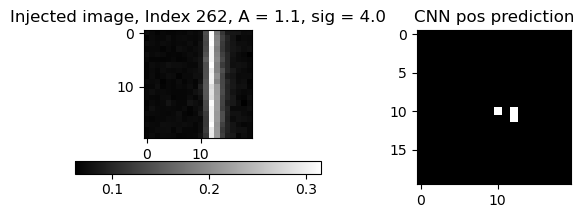

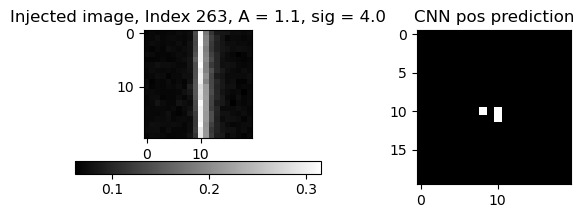

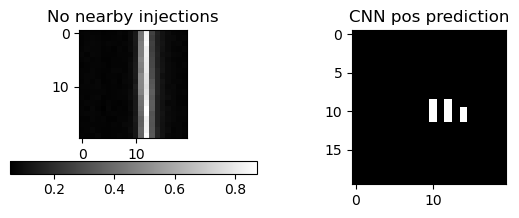

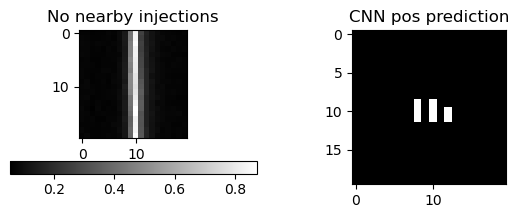

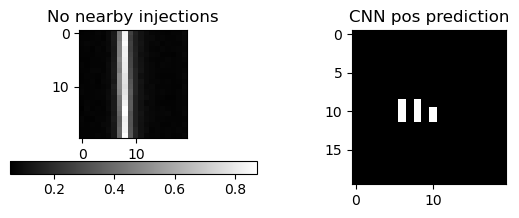

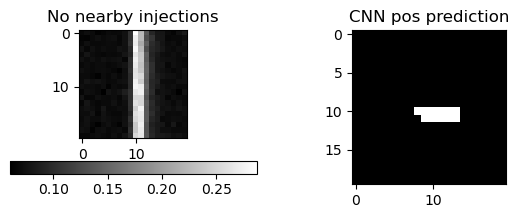

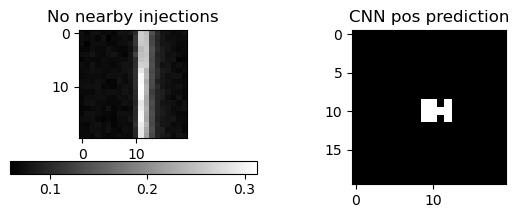

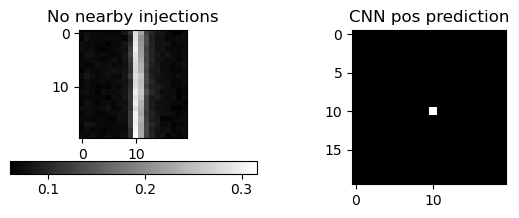

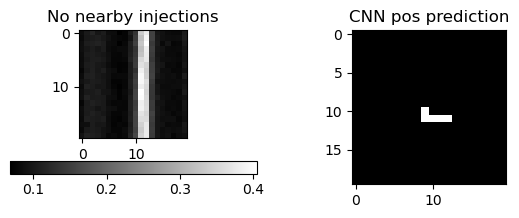

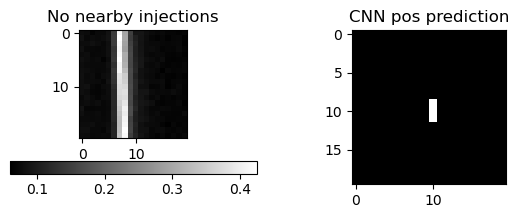

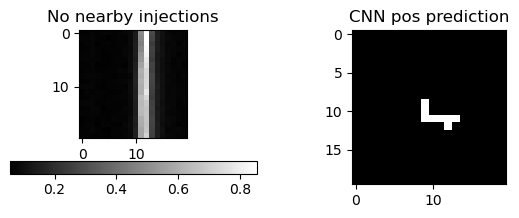

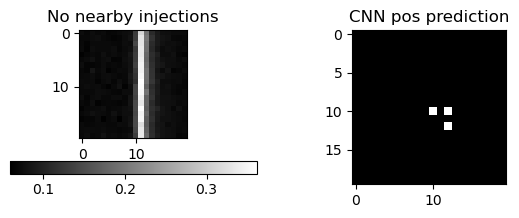

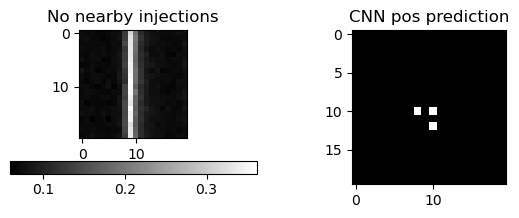

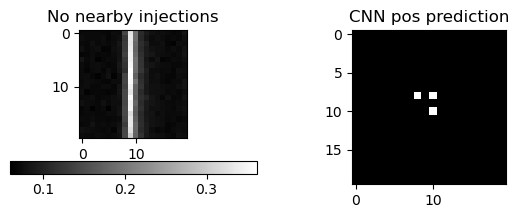

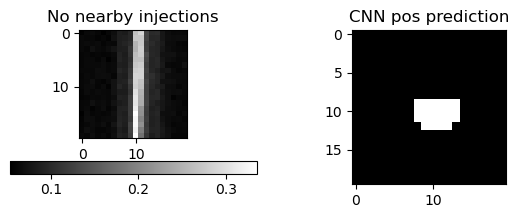

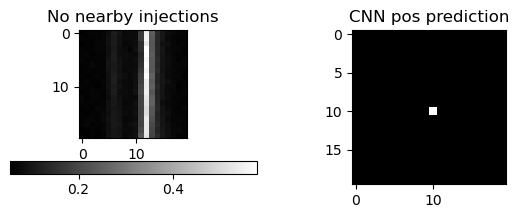

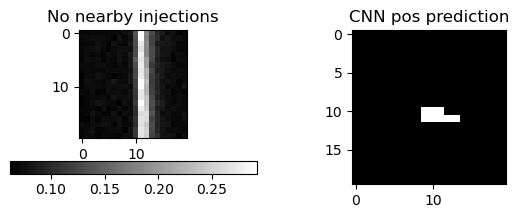

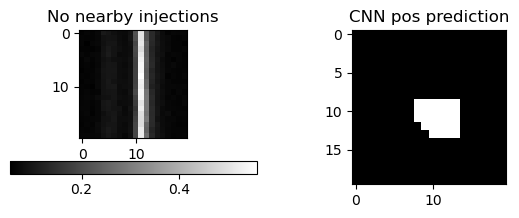

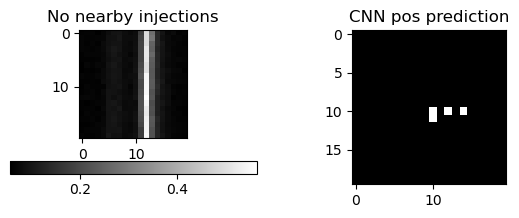

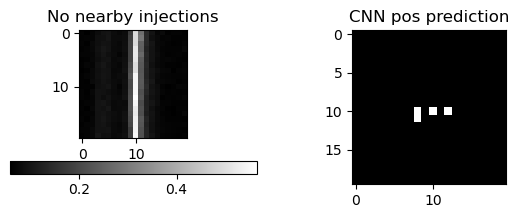

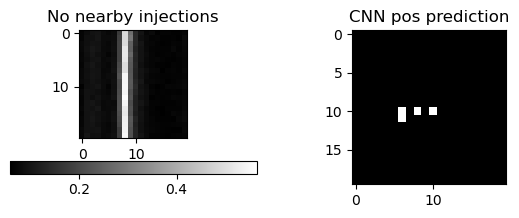

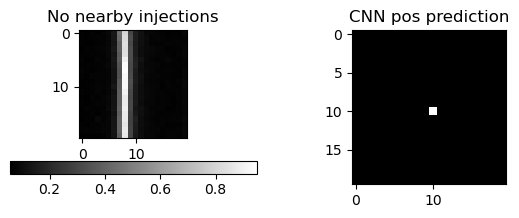

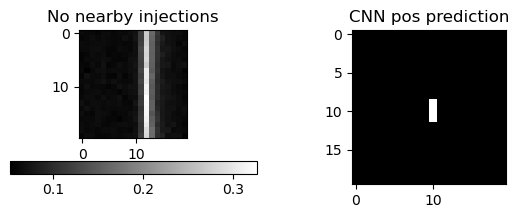

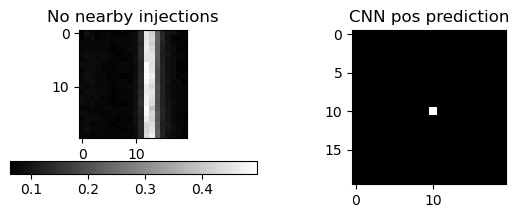

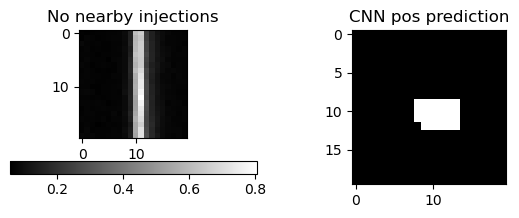

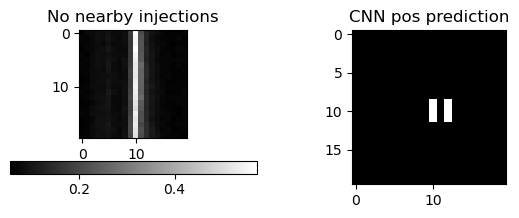

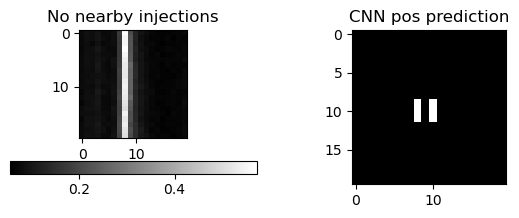

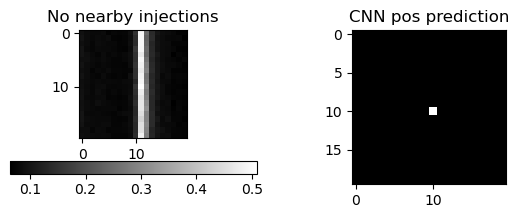

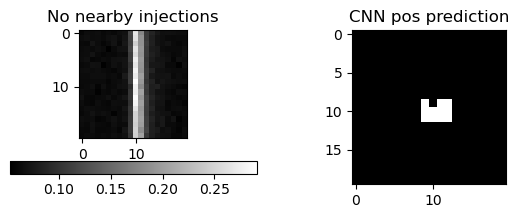

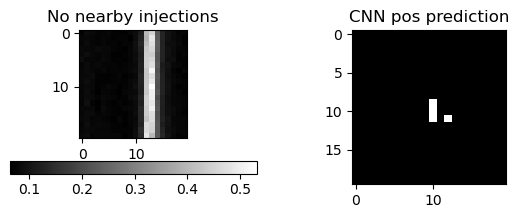

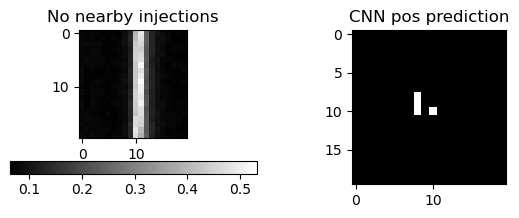

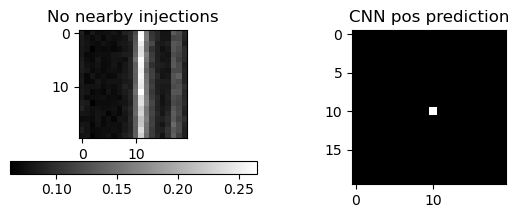

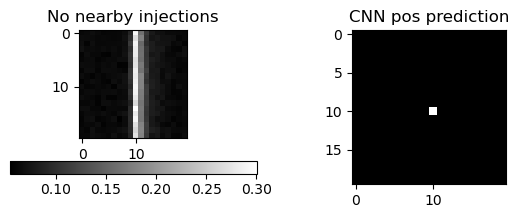

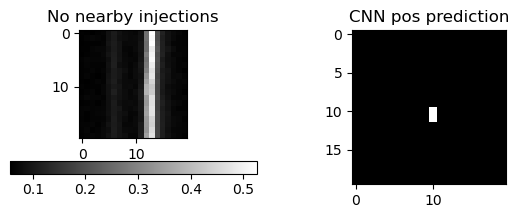

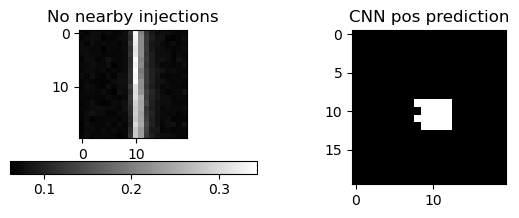

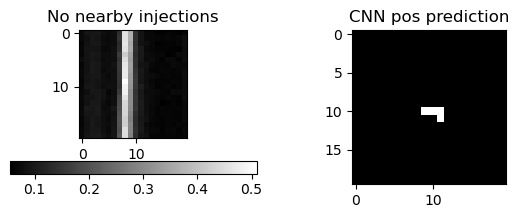

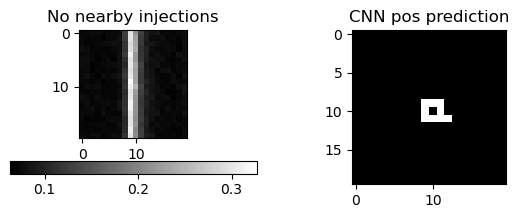

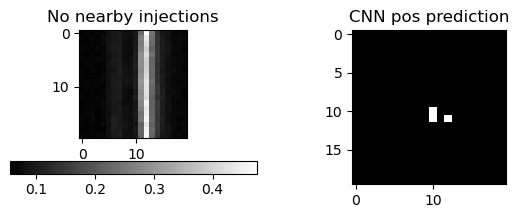

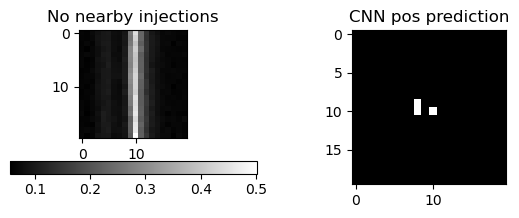

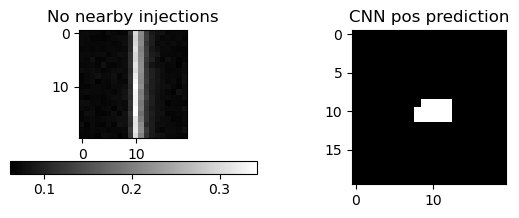

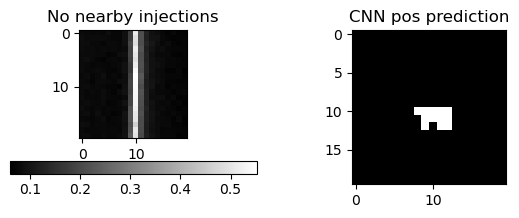

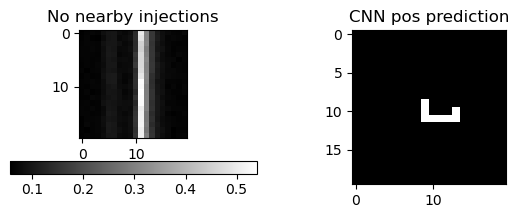

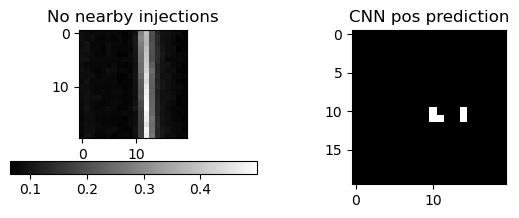

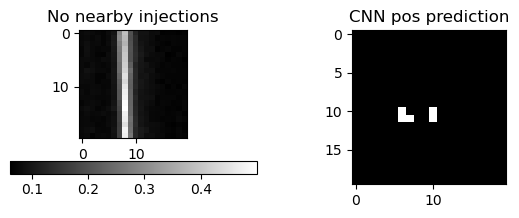

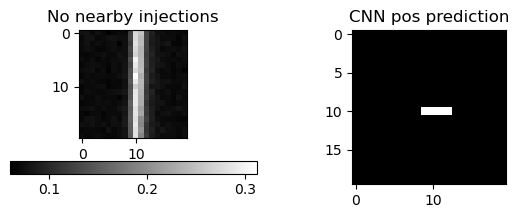

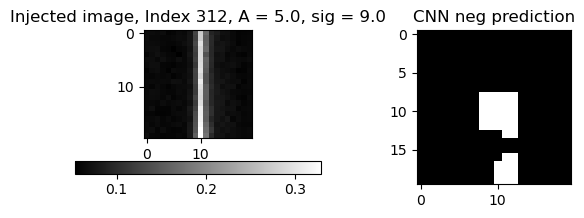

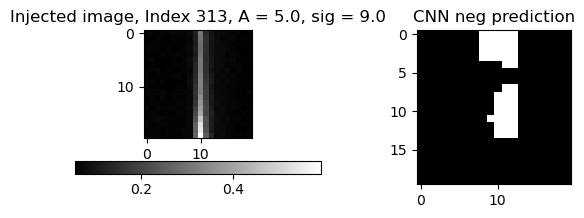

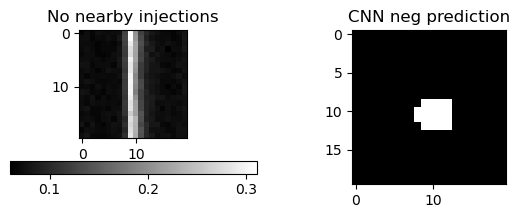

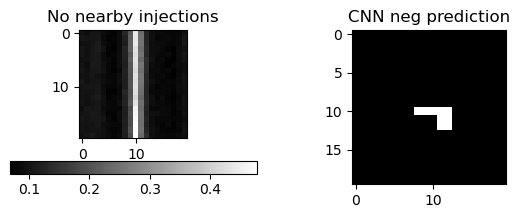

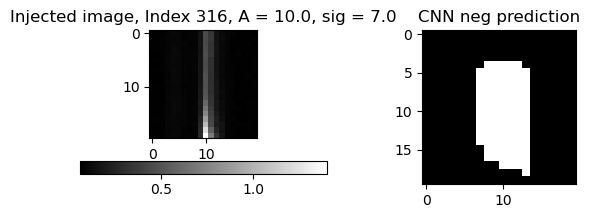

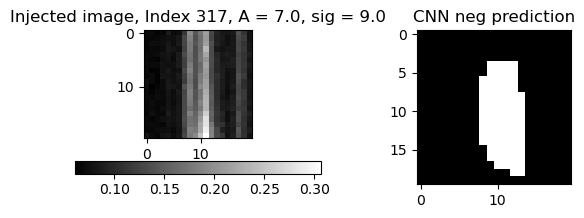

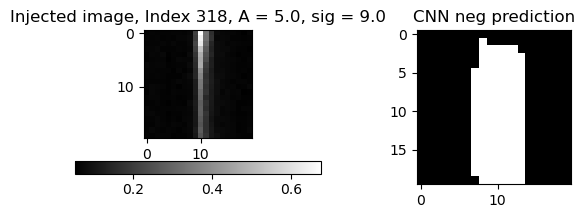

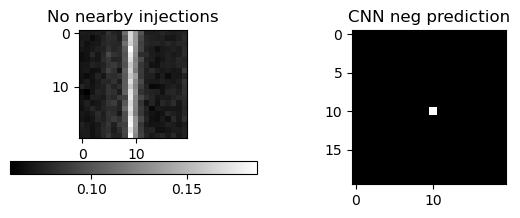

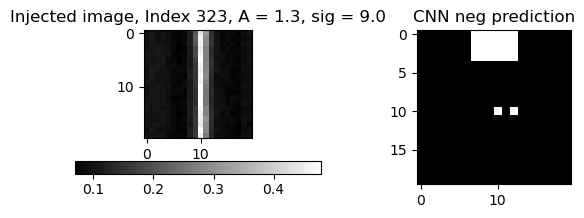

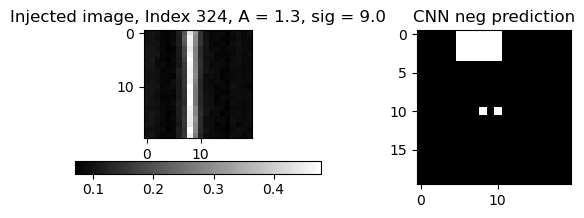

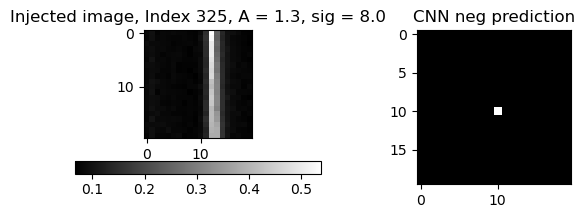

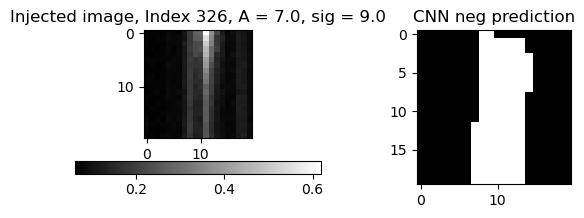

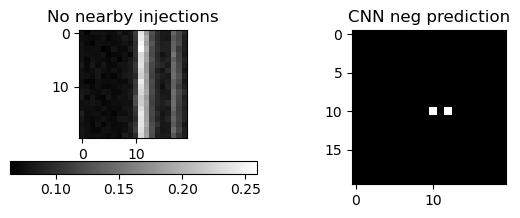

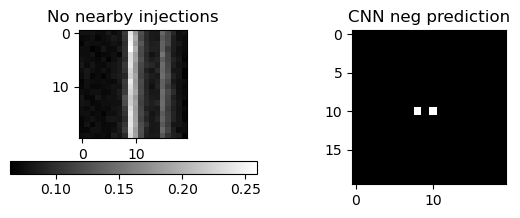

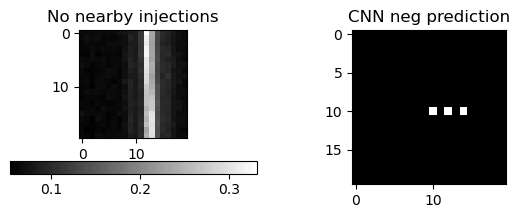

KeyboardInterrupt: 

<Figure size 700x200 with 0 Axes>

In [59]:
for index in df[df['dist_to_implant']>20].index:
    rff.inspect_stamp_and_map(df, index, posneg='pos', varthresh=.7,neweff="nosat_eff_data/", pdirec='predsarrays_average')

In [128]:
df.loc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020148032_000686_zg_c02_x_0001.
quad                                                          1
type                                                        pos
row_from_nn                                           38.714286
col_from_nn                                          240.071429
detection_size                                               42
closest_x                                                 250.0
closest_y                                                1761.0
Diff                                                  -0.071429
brightness_ranking                                            6
quadrant                                                      1
num_in_file_in_star                                        10.0
dup_indices                                                  []
is_smaller_dup                          

In [136]:
df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,38.714286,240.071429,42,250.0,1761.0,-0.071429,6,1,10.0,[],0.0,0.294508,49.0,250.0,1.50,4.0
1,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,42.061728,476.086420,81,487.0,435.0,0.913580,1,1,12.0,[],0.0,0.942243,53.0,486.0,10.00,5.0
2,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,46.745455,1430.381818,55,1441.0,1579.0,0.618182,2,1,6.0,[],0.0,1.398583,58.0,1441.0,1.20,5.0
3,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,71.750000,2256.916667,24,2266.0,1067.0,-0.916667,9,1,4.0,[],0.0,0.950146,82.0,2266.0,5.00,4.0
4,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,85.644068,2954.305085,59,2964.0,425.0,-0.305085,3,1,5.0,[],0.0,1.389831,97.0,2964.0,1.50,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1263,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2376.250000,2028.350000,20,2038.0,1087.0,-0.350000,0,3,22.0,[],0.0,11.755212,2398.0,2038.0,2.00,5.0
1264,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2401.161290,2028.387097,62,2038.0,1087.0,-0.387097,0,3,22.0,[],0.0,13.166982,2398.0,2038.0,2.00,5.0
1265,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2455.254237,2557.593220,59,2568.0,2214.0,0.406780,7,3,7.0,[],0.0,13.260478,2452.0,2568.0,2.00,5.0
1266,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2513.800000,1150.200000,5,1161.0,296.0,0.800000,2,3,8.0,[],0.0,71.804457,2452.0,1161.0,1.15,6.0
